# Лабораторная работа №1. Методы улучшения контраста изображений

Курс «Машинное зрение», **вариант 1-08**. Исходное изображение должно лежать рядом с ноутбуком: `requirements/image_v1-08.jpg`; рисунки для отчёта сохраняются в `figures/`.

Все вычисления, кроме AHE/CLAHE (`skimage.exposure.equalize_adapthist`), реализованы вручную на numpy и сверены с функциями scikit-image.

In [1]:
import math
from collections.abc import Callable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.axes import Axes
from matplotlib.colors import LogNorm, Normalize
from numpy.typing import NDArray
from skimage import io
from skimage.exposure import (
    adjust_gamma,
    equalize_adapthist,
    equalize_hist,
    rescale_intensity,
)
from skimage.feature import graycomatrix, graycoprops

P = 256  # число градаций яркости (8 бит)
BT601 = np.array([0.299, 0.587, 0.114])  # веса R, G, B для перевода в серое
IMAGE_PATH = Path("requirements/image_v1-08.jpg")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

## Общие функции

Используются во всех пунктах лабы.

In [2]:
type Pdf = Callable[[NDArray[np.float64]], NDArray[np.float64]]


def to_gray(img: NDArray[np.uint8]) -> NDArray[np.uint8]:
    """Переводит RGB-изображение в градации серого по стандарту BT.601.

    Args:
        img: NDArray[np.uint8] - Изображение формы (M, N, 3) или уже серое (M, N).

    Returns:
        NDArray[np.uint8] - Серое изображение формы (M, N) с яркостями [0; 255].

    Raises:
        ValueError: если у цветного изображения не 3 канала.

    """
    if img.ndim == 2:
        return img
    if img.shape[-1] != 3:
        msg = f"Ожидалось 3 канала (RGB), получено {img.shape[-1]}"
        raise ValueError(msg)
    return np.round(img @ BT601).astype(np.uint8)


def glcm(img: NDArray[np.uint8], d: int, alpha: int) -> NDArray[np.float64]:
    """Считает нормированную матрицу Харалика (GLCM) размера P × P.

    Элемент g[p, q] — доля пар соседних пикселей, где у пикселя яркость p,
    а у соседа на расстоянии d в направлении alpha — яркость q.

    Args:
        img: NDArray[np.uint8] - Серое изображение формы (M, N).
        d: int - Расстояние до соседа в пикселях, не меньше 1.
        alpha: int - Направление в градусах: 0 — сосед справа, 90 — сосед снизу.

    Returns:
        NDArray[np.float64] - Матрица формы (P, P), сумма элементов равна 1.

    Raises:
        ValueError: если alpha не 0 и не 90 или d вне [1; размер изображения).

    """
    if d < 1:
        msg = f"Расстояние d должно быть >= 1, получено {d}"
        raise ValueError(msg)
    if alpha == 0:
        ref, nbr = img[:, :-d], img[:, d:]
    elif alpha == 90:
        ref, nbr = img[:-d, :], img[d:, :]
    else:
        msg = f"Поддерживаются углы 0 и 90, получено {alpha}"
        raise ValueError(msg)
    if ref.size == 0:
        msg = f"Расстояние d={d} не меньше размера изображения {img.shape}"
        raise ValueError(msg)
    g = np.zeros((P, P))
    np.add.at(g, (ref.ravel(), nbr.ravel()), 1)
    return g / g.sum()


def haralick_contrast(g: NDArray[np.float64]) -> float:
    """Считает контраст Харалика: сумму (p - q)² · g[p, q] по всей матрице.

    Args:
        g: NDArray[np.float64] - Нормированная матрица Харалика.

    Returns:
        float - Контраст Харалика.

    """
    p, q = np.indices(g.shape)
    return float(((p - q) ** 2 * g).sum())


def contrast_stats(img: NDArray[np.uint8]) -> dict[str, float]:
    """Считает статистические характеристики и контрасты серого изображения.

    Экстремумы приводятся к int, иначе сумма a_max + a_min переполнит uint8.

    Args:
        img: NDArray[np.uint8] - Серое изображение формы (M, N).

    Returns:
        dict[str, float] - Характеристики: a_min, a_max, range_usage_pct,
            n_levels, mean, var, michelson, global, rms, haralick (d=1, alpha=0).

    """
    a_min, a_max = int(img.min()), int(img.max())
    width = a_max - a_min
    return {
        "a_min": a_min,
        "a_max": a_max,
        "range_usage_pct": width / (P - 1) * 100,
        "n_levels": len(np.unique(img)),
        "mean": float(img.mean()),
        "var": float(img.var()),
        "michelson": width / (a_max + a_min) if a_max + a_min else 0.0,
        "global": width / (P - 1),
        "rms": float(img.std()),
        "haralick": haralick_contrast(glcm(img, 1, 0)),
    }


def show_glcm(
    ax: Axes, g: NDArray[np.float64], title: str, norm: Normalize | None = None
) -> None:
    """Рисует матрицу Харалика в логарифмической шкале.

    Нулевые элементы закрашиваются чёрным.

    Args:
        ax: Axes - Оси matplotlib, на которых рисовать.
        g: NDArray[np.float64] - Нормированная матрица Харалика.
        title: str - Заголовок графика.
        norm: Normalize | None - Общая шкала цветов для сравнения нескольких матриц;
            по умолчанию логарифмическая по самой матрице.

    """
    cmap = plt.get_cmap("magma").with_extremes(bad="black")
    image = ax.imshow(
        np.ma.masked_equal(g, 0),
        cmap=cmap,
        norm=norm if norm is not None else LogNorm(),
    )
    ax.set_title(title)
    ax.set_xlabel("q — яркость соседа")
    ax.set_ylabel("p — яркость пикселя")
    ax.figure.colorbar(image, ax=ax, label="доля пар $g_{pq}$ (лог. шкала)")


def window(
    img: NDArray[np.uint8], lo: float, hi: float, gamma: float = 1.0
) -> NDArray[np.uint8]:
    """Отображает яркостное окно [lo; hi] на [0; P - 1] с гамма-коррекцией.

    Яркости ниже lo становятся 0, выше hi — P - 1, внутри окна доля
    (a - lo) / (hi - lo) возводится в степень gamma. При gamma = 1 это
    линейное окно, а при lo = a_min и hi = a_max — линейное контрастирование
    всего динамического диапазона. gamma < 1 осветляет, gamma > 1 затемняет.

    Args:
        img: NDArray[np.uint8] - Серое изображение (или массив уровней яркости).
        lo: float - Нижняя граница окна.
        hi: float - Верхняя граница окна, больше lo.
        gamma: float - Показатель гамма-коррекции, больше 0.

    Returns:
        NDArray[np.uint8] - Преобразованное изображение той же формы.

    Raises:
        ValueError: если hi <= lo или gamma <= 0.

    """
    if hi <= lo:
        msg = f"Пустое окно: hi={hi} должно быть больше lo={lo}"
        raise ValueError(msg)
    if gamma <= 0:
        msg = f"Показатель gamma должен быть больше 0, получено {gamma}"
        raise ValueError(msg)
    x = (np.clip(img.astype(np.float64), lo, hi) - lo) / (hi - lo)
    return np.round(x**gamma * (P - 1)).astype(np.uint8)


def histogram(img: NDArray[np.uint8]) -> NDArray[np.intp]:
    """Считает гистограмму яркостей: число пикселей каждой яркости 0…P - 1.

    Args:
        img: NDArray[np.uint8] - Серое изображение.

    Returns:
        NDArray[np.intp] - Массив длины P, элемент h[p] — число пикселей яркости p.

    """
    return np.bincount(img.ravel(), minlength=P)


def show_hist(ax: Axes, img: NDArray[np.uint8], title: str) -> None:
    """Рисует гистограмму яркостей изображения.

    Args:
        ax: Axes - Оси matplotlib, на которых рисовать.
        img: NDArray[np.uint8] - Серое изображение.
        title: str - Заголовок графика.

    """
    ax.bar(np.arange(P), histogram(img), width=1.0)
    ax.set_xlim(-0.5, P - 0.5)
    ax.set_title(title)
    ax.set_xlabel("яркость p")
    ax.set_ylabel("число пикселей h(p)")


def cumulative_histogram(img: NDArray[np.uint8]) -> NDArray[np.float64]:
    """Считает накопленную гистограмму: долю пикселей с яркостью не больше p.

    Args:
        img: NDArray[np.uint8] - Серое изображение.

    Returns:
        NDArray[np.float64] - Массив длины P, H[p] — доля пикселей с яркостью <= p.

    """
    return np.cumsum(histogram(img)) / img.size


def target_cdf(
    pdf: Pdf, n: int = 4096
) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    """Считает функцию распределения F(z) желаемой плотности на [0; P - 1].

    Плотность задаётся без нормировки: F получается интегрированием
    методом трапеций на сетке из n точек и делением на полный интеграл.

    Args:
        pdf: Pdf - Желаемая плотность f(z) >= 0 как функция от массива яркостей.
        n: int - Число точек сетки.

    Returns:
        tuple[NDArray[np.float64], NDArray[np.float64]] - Сетка z и значения
            F(z), где F(0) = 0 и F(P - 1) = 1.

    Raises:
        ValueError: если плотность где-то отрицательна или её интеграл равен 0.

    """
    z = np.linspace(0, P - 1, n)
    f = np.asarray(pdf(z), dtype=np.float64)
    if (f < 0).any():
        msg = "Плотность распределения должна быть неотрицательной"
        raise ValueError(msg)
    cdf = np.concatenate([[0.0], np.cumsum((f[1:] + f[:-1]) / 2 * np.diff(z))])
    if cdf[-1] <= 0:
        msg = "Интеграл плотности распределения равен 0"
        raise ValueError(msg)
    return z, cdf / cdf[-1]


def match_lut(img: NDArray[np.uint8], pdf: Pdf) -> NDArray[np.uint8]:
    """Строит передаточную функцию выравнивания гистограммы по распределению.

    g(a) = F⁻¹(H(a)): накопленная гистограмма H делает яркости приблизительно
    равномерными на [0; 1], обратная функция распределения F⁻¹ переводит их
    в желаемое распределение. Для равномерной плотности это классическое выравнивание
    g(a) = (P - 1) · H(a).

    Args:
        img: NDArray[np.uint8] - Серое изображение.
        pdf: Pdf - Желаемая плотность распределения яркостей (без нормировки).

    Returns:
        NDArray[np.uint8] - Таблица длины P; результат применяется как lut[img].

    """
    z, cdf = target_cdf(pdf)
    return np.round(np.interp(cumulative_histogram(img), cdf, z)).astype(np.uint8)


def tile_size(shape: tuple[int, ...], tiles: int) -> tuple[int, int]:
    """Считает размер фрагмента (окна) при разбиении изображения на tiles × tiles.

    Args:
        shape: tuple[int, ...] - Форма изображения (M, N).
        tiles: int - Число фрагментов по каждой стороне, не меньше 1.

    Returns:
        tuple[int, int] - Высота и ширина фрагмента в пикселях.

    Raises:
        ValueError: если tiles < 1.

    """
    if tiles < 1:
        msg = f"Число фрагментов tiles должно быть >= 1, получено {tiles}"
        raise ValueError(msg)
    return math.ceil(shape[0] / tiles), math.ceil(shape[1] / tiles)


def clahe(img: NDArray[np.uint8], tiles: int, clip_limit: float) -> NDArray[np.uint8]:
    """Выполняет адаптивное выравнивание гистограммы с ограничением контраста.

    Изображение делится на tiles × tiles фрагментов, в каждом гистограмма
    отсекается на уровне clip_limit (доля от числа пикселей фрагмента) и
    выравнивается; между фрагментами — билинейная интерполяция. При
    clip_limit = 1 отсечения нет — это обычное AHE.

    Args:
        img: NDArray[np.uint8] - Серое изображение.
        tiles: int - Число фрагментов по каждой стороне.
        clip_limit: float - Уровень отсечения в (0; 1].

    Returns:
        NDArray[np.uint8] - Выровненное изображение той же формы.

    Raises:
        ValueError: если clip_limit вне (0; 1] или tiles < 1.

    """
    if not 0 < clip_limit <= 1:
        msg = (
            f"Уровень отсечения clip_limit должен быть в (0; 1], получено {clip_limit}"
        )
        raise ValueError(msg)
    out = equalize_adapthist(
        img, kernel_size=tile_size(img.shape, tiles), clip_limit=clip_limit, nbins=P
    )
    return np.round(out * (P - 1)).astype(np.uint8)


def tile_equalize(img: NDArray[np.uint8], tiles: int) -> NDArray[np.uint8]:
    """Выравнивает гистограмму в каждом фрагменте отдельно, без интерполяции.

    Демонстрационная версия адаптивного выравнивания: на границах
    фрагментов появляются «швы», которые AHE устраняет интерполяцией.

    Args:
        img: NDArray[np.uint8] - Серое изображение.
        tiles: int - Число фрагментов по каждой стороне.

    Returns:
        NDArray[np.uint8] - Изображение с выровненными фрагментами.

    """
    out = np.empty_like(img)
    rows = np.array_split(np.arange(img.shape[0]), tiles)
    cols = np.array_split(np.arange(img.shape[1]), tiles)
    for r in rows:
        for c in cols:
            block = img[np.ix_(r, c)]
            out[np.ix_(r, c)] = match_lut(block, np.ones_like)[block]
    return out

## 1. Загрузка и визуализация изображения

### 1.a) Числовые характеристики изображения

In [3]:
rgb = io.imread(IMAGE_PATH)
height, width, channels = rgb.shape
bits = rgb.dtype.itemsize * 8
display(
    Markdown(
        "| Размерность изображения | Число цветовых каналов | Яркостное разрешение |\n"
        "|:---:|:---:|:---:|\n"
        f"| {width} × {height} пикс. (ширина × высота) | {channels} (RGB) "
        f"| {bits} бит на канал ({2**bits} градаций, `{rgb.dtype}`) |"
    )
)

| Размерность изображения | Число цветовых каналов | Яркостное разрешение |
|:---:|:---:|:---:|
| 702 × 599 пикс. (ширина × высота) | 3 (RGB) | 8 бит на канал (256 градаций, `uint8`) |

### 1.б) Перевод в градации серого

Изображение цветное (3 канала) → приводим к одному каналу по стандарту BT.601 (как `rgb2gray` в MATLAB):

$$Y = 0.299R + 0.587G + 0.114B, \quad Y \in [0; 255]$$

Зелёный имеет наибольший вес, потому что глаз наиболее чувствителен к нему.

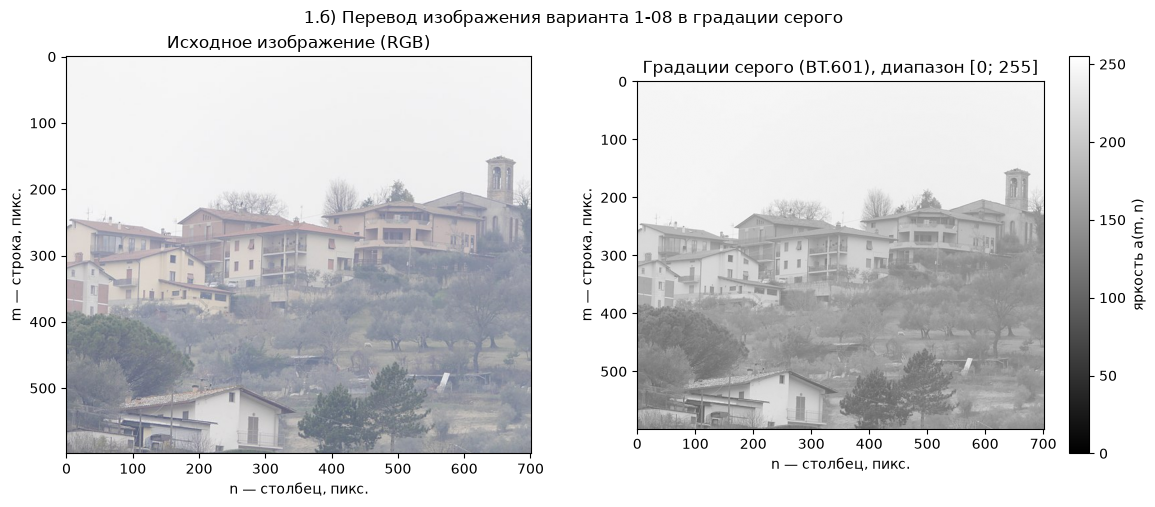

In [4]:
gray = to_gray(rgb)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb)
axes[0].set_title("Исходное изображение (RGB)")
# vmin/vmax обязательны: иначе matplotlib сам растянет контраст и исказит картину
image = axes[1].imshow(gray, cmap="gray", vmin=0, vmax=P - 1)
axes[1].set_title("Градации серого (BT.601), диапазон [0; 255]")
fig.colorbar(image, ax=axes[1], label="яркость a(m, n)")
for ax in axes:
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
fig.suptitle("1.б) Перевод изображения варианта 1-08 в градации серого")
fig.tight_layout()
fig.savefig(FIGURES / "01b_gray.png", dpi=150)
plt.show()

### 1.в) Статистические характеристики изображения

In [5]:
s = contrast_stats(gray)
display(
    Markdown(
        "| Возможный диапазон яркостей | Динамический диапазон "
        "| % использования яркостного диапазона | Число различных яркостей |\n"
        "|:---:|:---:|:---:|:---:|\n"
        f"| [0; {P - 1}] | [{s['a_min']}; {s['a_max']}] "
        f"| {s['range_usage_pct']:.1f}% | {s['n_levels']} |"
    )
)

| Возможный диапазон яркостей | Динамический диапазон | % использования яркостного диапазона | Число различных яркостей |
|:---:|:---:|:---:|:---:|
| [0; 255] | [80; 255] | 68.6% | 172 |

In [6]:
rows = [
    (
        "Динамический диапазон",
        r"$[a_{min};\ a_{max}]$",
        f"[{s['a_min']}; {s['a_max']}]",
    ),
    (
        "% использования яркостного диапазона",
        r"$\frac{a_{max}-a_{min}}{P-1}\cdot 100\%$",
        f"{s['range_usage_pct']:.2f}%",
    ),
    ("Число различных яркостей", r"$\#\{a(m,n)\}$", f"{s['n_levels']}"),
    (
        "Средняя яркость",
        r"$\bar a = \frac{1}{MN}\sum_{m,n} a(m,n)$",
        f"{s['mean']:.2f}",
    ),
    (
        "Дисперсия яркости",
        r"$D[a] = \frac{1}{MN}\sum_{m,n} (a(m,n)-\bar a)^2$",
        f"{s['var']:.2f}",
    ),
    (
        "Контраст Михельсона",
        r"$C_{Mich} = \frac{a_{max}-a_{min}}{a_{max}+a_{min}}$",
        f"{s['michelson']:.4f}",
    ),
    (
        "Глобальный контраст",
        r"$C_g = \frac{a_{max}-a_{min}}{P-1}$",
        f"{s['global']:.4f}",
    ),
    (
        "Среднеквадратический контраст",
        r"$C_{rms} = \sigma_a = \sqrt{D[a]}$",
        f"{s['rms']:.2f}",
    ),
    (
        r"Контраст Харалика ($d=1,\ \alpha=0^\circ$)",
        r"$C_{GLCM} = \sum_{p,q} (p-q)^2\, g_{pq}$",
        f"{s['haralick']:.2f}",
    ),
]
display(
    Markdown(
        "| Характеристика | Формула | Значение |\n|:---|:---:|:---:|\n"
        + "\n".join(
            f"| {name} | {formula} | {value} |" for name, formula, value in rows
        )
    )
)

| Характеристика | Формула | Значение |
|:---|:---:|:---:|
| Динамический диапазон | $[a_{min};\ a_{max}]$ | [80; 255] |
| % использования яркостного диапазона | $\frac{a_{max}-a_{min}}{P-1}\cdot 100\%$ | 68.63% |
| Число различных яркостей | $\#\{a(m,n)\}$ | 172 |
| Средняя яркость | $\bar a = \frac{1}{MN}\sum_{m,n} a(m,n)$ | 191.63 |
| Дисперсия яркости | $D[a] = \frac{1}{MN}\sum_{m,n} (a(m,n)-\bar a)^2$ | 1955.04 |
| Контраст Михельсона | $C_{Mich} = \frac{a_{max}-a_{min}}{a_{max}+a_{min}}$ | 0.5224 |
| Глобальный контраст | $C_g = \frac{a_{max}-a_{min}}{P-1}$ | 0.6863 |
| Среднеквадратический контраст | $C_{rms} = \sigma_a = \sqrt{D[a]}$ | 44.22 |
| Контраст Харалика ($d=1,\ \alpha=0^\circ$) | $C_{GLCM} = \sum_{p,q} (p-q)^2\, g_{pq}$ | 45.43 |

#### Матрица Харалика

Матрица Харалика $G_{\alpha,d}$ размера $P \times P$: элемент $g_{pq}$ — доля пар пикселей, где у пикселя яркость $p$, а у соседа на расстоянии $d$ в направлении $\alpha$ — яркость $q$. $\alpha = 0^\circ$ — сосед справа, $\alpha = 90^\circ$ — сосед по вертикали (соглашение scikit-image; на контраст направление «вверх/вниз» не влияет, т.к. $(p-q)^2 = (q-p)^2$).

Контраст Харалика $C_{GLCM} = \sum_{p,q}(p-q)^2 g_{pq}$ при $\sum g_{pq} = 1$. Это классическое определение контраста Харалика (так же считают `graycoprops` в scikit-image и MATLAB). Встречаются и другие записи: с множителем $\frac{1}{P^2}$ — тот же контраст в другом масштабе (всегда меньше 1) и с $|p-q|$ вместо $(p-q)^2$ — это другой признак (в scikit-image он называется dissimilarity). Их значения нельзя сравнивать с общепринятым контрастом Харалика. Матрицы показаны в логарифмической шкале (значения различаются на порядки), нули — чёрным.

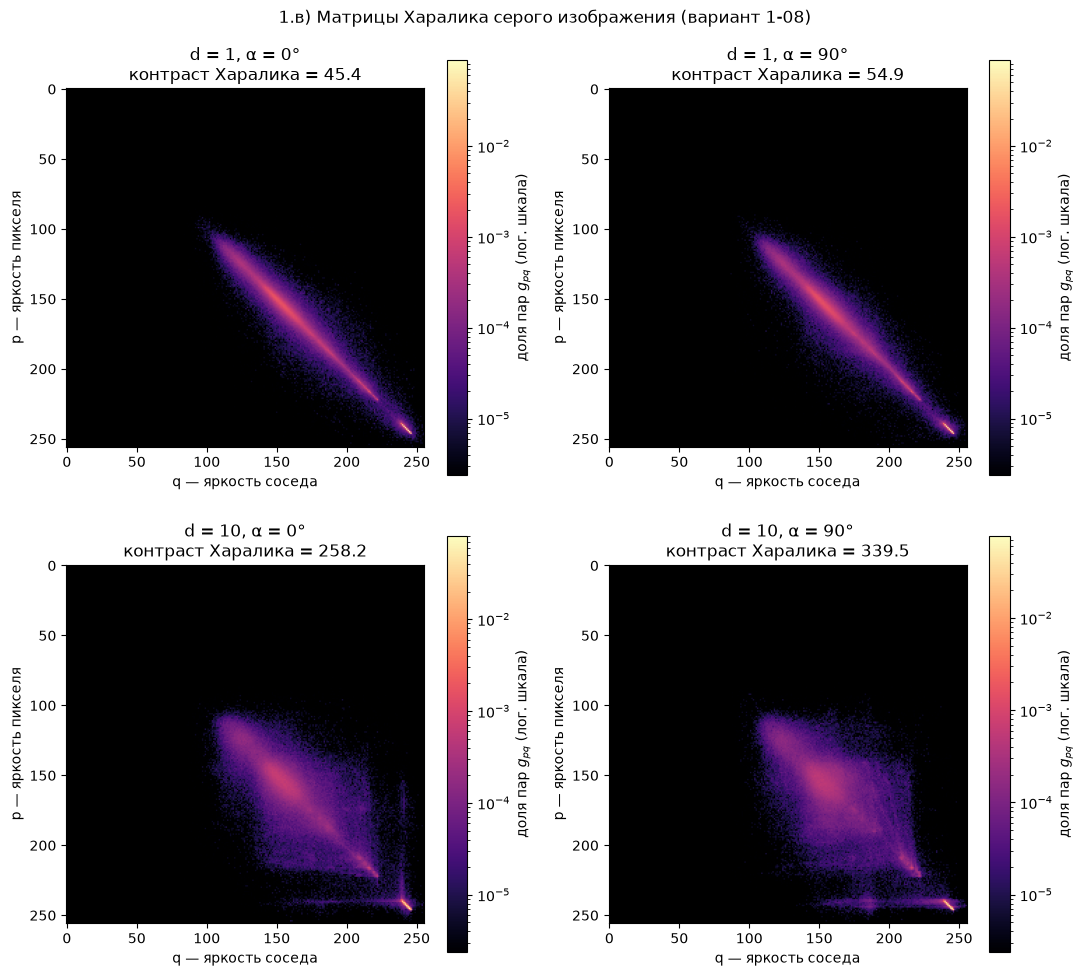

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row, d in enumerate((1, 10)):
    for col, alpha in enumerate((0, 90)):
        g = glcm(gray, d, alpha)
        show_glcm(
            axes[row, col],
            g,
            f"d = {d}, α = {alpha}°\nконтраст Харалика = {haralick_contrast(g):.1f}",
        )
fig.suptitle("1.в) Матрицы Харалика серого изображения (вариант 1-08)")
fig.tight_layout()
fig.savefig(FIGURES / "01c_glcm.png", dpi=150)
plt.show()

In [8]:
for d in (1, 10):
    for alpha in (0, 90):
        ours = glcm(gray, d, alpha)
        ref = graycomatrix(gray, [d], [np.deg2rad(alpha)], levels=P, normed=True)
        assert np.allclose(ours, ref[:, :, 0, 0])
        assert np.isclose(haralick_contrast(ours), graycoprops(ref, "contrast")[0, 0])
print("Матрицы и контраст Харалика совпадают со scikit-image для всех d и α")

Матрицы и контраст Харалика совпадают со scikit-image для всех d и α


### Выводы по пункту 1

- Изображение 702 × 599, 3 канала, 8 бит на канал. После перевода в серое яркости лежат в [80; 255]: тёмная треть шкалы (0–79) не используется совсем — туман добавляет рассеянный свет и «поднимает» самые тёмные точки.
- Средняя яркость 191.6 — изображение светлое; σ = 44.2 — разброс яркостей умеренный. Внутри динамического диапазона используются почти все уровни (172 из 176).
- Контраст Михельсона (0.52) и глобальный контраст (0.69) зависят только от двух крайних яркостей, а их задают единичные пиксели: a_max = 255 — у 10 пикселей-выбросов на границах объектов (само небо не ярче 249), a_min = 80 — у одного пикселя. 98 % пикселей лежат в [114; 246] — это лишь ~52 % шкалы, а не 69 %. Поэтому эти метрики плохо описывают «мыльность» картинки; среднеквадратический контраст учитывает все пиксели.
- Контраст Харалика при d = 1 мал (45 по горизонтали, 55 по вертикали): соседние пиксели почти одинаковы, матрица прижата к диагонали. При d = 10 он растёт примерно в 6 раз (258 и 340), матрица «расплывается»: далёкие пиксели чаще принадлежат разным объектам.
- Яркое пятно в правом нижнем углу матриц (≈ 240–250) — небо: большая однородная светлая область. При d = 10 от него отходят горизонтальная и вертикальная «полосы» (p или q ≈ 240) — это пары «небо — дом/дерево» на линии горизонта.
- По вертикали контраст выше, чем по горизонтали: в сцене преобладают горизонтальные структуры (горизонт, ряды крыш, этажи, ярусы холма), поэтому вдоль строки яркость меняется медленнее, чем поперёк.
- Итог: изображение низкоконтрастное и использует ~69% шкалы — его нужно контрастировать (пункт 2).

## 2. Контрастирование в яркостных окнах

### 2.а) Масштабирование динамического диапазона на [0; 255]

Линейное контрастирование переводит динамический диапазон $[a_{min}; a_{max}]$ в максимально возможный $[0; P-1]$ передаточной функцией

$$g(a) = \frac{a - a_{min}}{a_{max} - a_{min}}\,(P - 1).$$

Передаточная функция $g(a)$ показывает, во что превращается каждая исходная яркость $a$. Здесь она линейна: самый тёмный пиксель становится чёрным (0), самый светлый — белым (255), остальные растягиваются пропорционально с коэффициентом $k = \frac{P-1}{a_{max} - a_{min}}$.

Для сравнения показано растяжение по 1-му и 99-му перцентилям яркости: обрезается ~1 % пикселей с краёв гистограммы, зато её редкие хвосты не ограничивают растяжение.

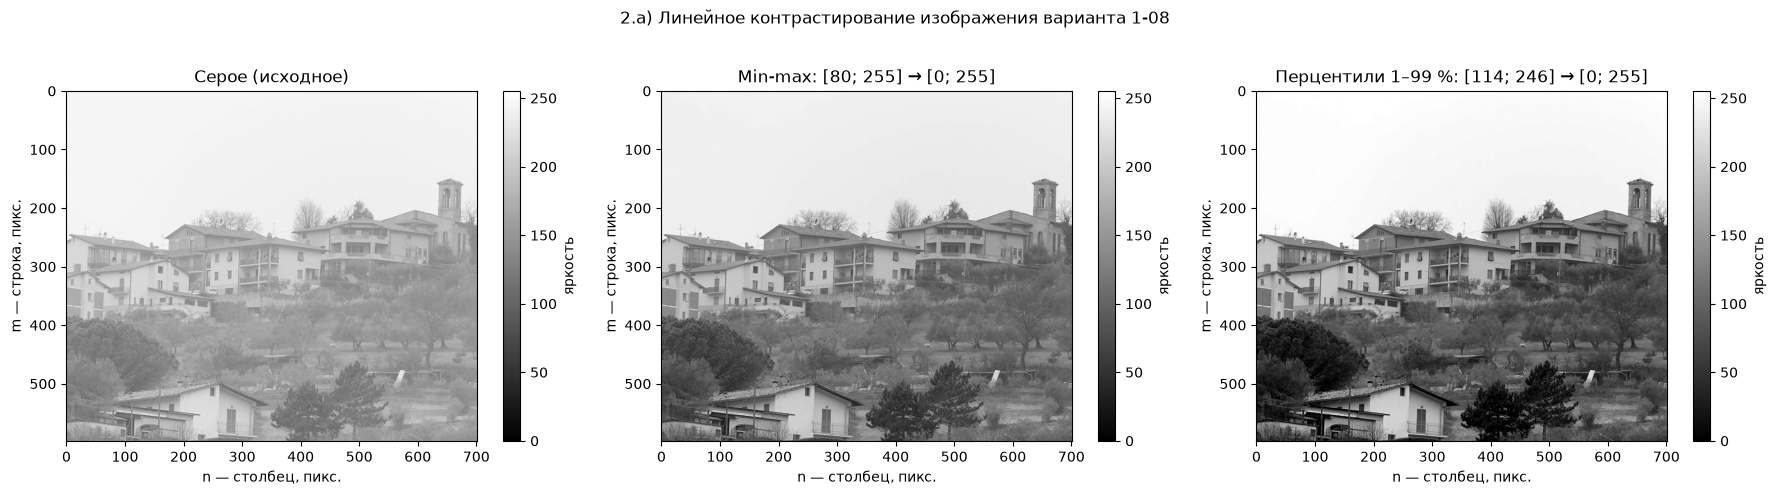

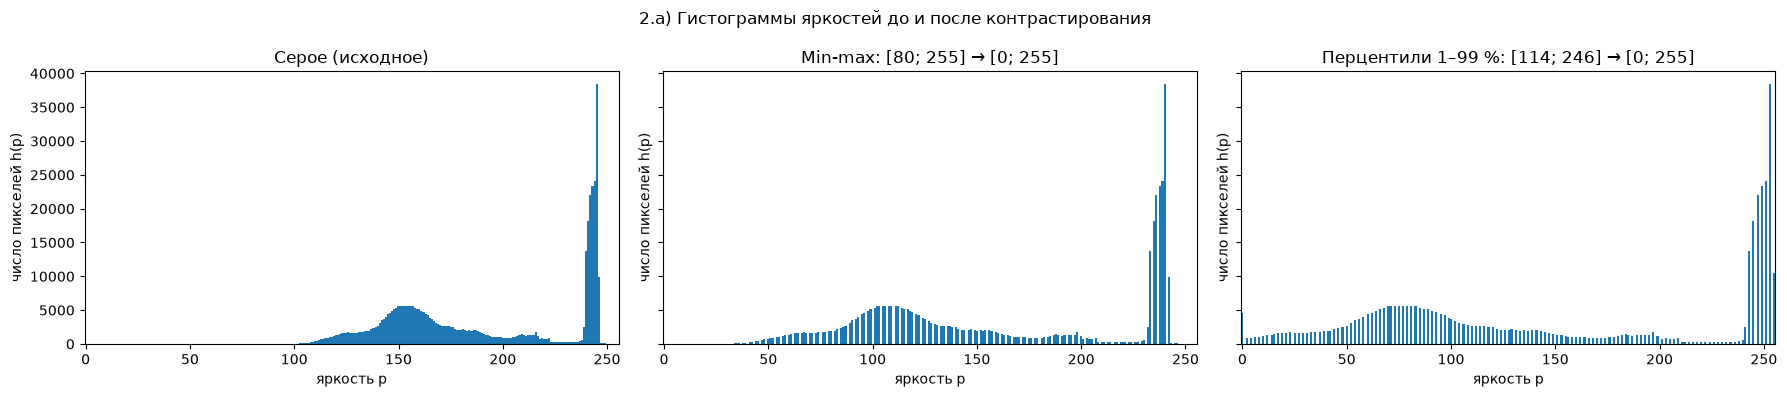

In [9]:
contrasted = window(gray, s["a_min"], s["a_max"])
p_lo, p_hi = np.percentile(gray, [1, 99])
robust = window(gray, p_lo, p_hi)
stretch_images = {
    "Серое (исходное)": gray,
    f"Min-max: [{s['a_min']}; {s['a_max']}] → [0; 255]": contrasted,
    f"Перцентили 1–99 %: [{p_lo:.0f}; {p_hi:.0f}] → [0; 255]": robust,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, img) in zip(axes, stretch_images.items(), strict=True):
    image = ax.imshow(img, cmap="gray", vmin=0, vmax=P - 1)
    ax.set_title(title)
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
    fig.colorbar(image, ax=ax, label="яркость", shrink=0.8)
fig.suptitle("2.а) Линейное контрастирование изображения варианта 1-08")
fig.tight_layout()
fig.savefig(FIGURES / "02a_stretch.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, (title, img) in zip(axes, stretch_images.items(), strict=True):
    show_hist(ax, img, title)
fig.suptitle("2.а) Гистограммы яркостей до и после контрастирования")
fig.tight_layout()
fig.savefig(FIGURES / "02a_hist.png", dpi=150)
plt.show()

In [10]:
stats = {name: contrast_stats(img) for name, img in stretch_images.items()}
fmt = {
    "Динамический диапазон": lambda t: f"[{t['a_min']}; {t['a_max']}]",
    "% использования яркостного диапазона": lambda t: f"{t['range_usage_pct']:.1f}%",
    "Число различных яркостей": lambda t: f"{t['n_levels']}",
    "Средняя яркость": lambda t: f"{t['mean']:.2f}",
    "Дисперсия яркости": lambda t: f"{t['var']:.2f}",
    "Контраст Михельсона": lambda t: f"{t['michelson']:.4f}",
    "Глобальный контраст": lambda t: f"{t['global']:.4f}",
    "Среднеквадратический контраст": lambda t: f"{t['rms']:.2f}",
    r"Контраст Харалика ($d=1,\ \alpha=0^\circ$)": lambda t: f"{t['haralick']:.2f}",
}
header = (
    "| Характеристика | " + " | ".join(stats) + " |\n|:---|" + ":---:|" * len(stats)
)
body = "\n".join(
    f"| {name} | " + " | ".join(f(t) for t in stats.values()) + " |"
    for name, f in fmt.items()
)
display(Markdown(header + "\n" + body))

| Характеристика | Серое (исходное) | Min-max: [80; 255] → [0; 255] | Перцентили 1–99 %: [114; 246] → [0; 255] |
|:---|:---:|:---:|:---:|
| Динамический диапазон | [80; 255] | [0; 255] | [0; 255] |
| % использования яркостного диапазона | 68.6% | 100.0% | 100.0% |
| Число различных яркостей | 172 | 172 | 133 |
| Средняя яркость | 191.63 | 162.66 | 149.99 |
| Дисперсия яркости | 1955.04 | 4151.48 | 7251.78 |
| Контраст Михельсона | 0.5224 | 1.0000 | 1.0000 |
| Глобальный контраст | 0.6863 | 1.0000 | 1.0000 |
| Среднеквадратический контраст | 44.22 | 64.43 | 85.16 |
| Контраст Харалика ($d=1,\ \alpha=0^\circ$) | 45.43 | 96.52 | 165.66 |

> **Далее во всех пунктах исходным изображением считается `contrasted`** — результат min-max контрастирования.

### 2.б) Контрастирование в яркостных окнах

Яркостное окно $[w_{min}; w_{max}]$ отображается на весь диапазон $[0; P-1]$, а яркости вне окна насыщаются:

$$g(a) = \begin{cases} 0, & a < w_{min} \\ \dfrac{a - w_{min}}{w_{max} - w_{min}}\,(P-1), & w_{min} \le a \le w_{max} \\ P-1, & a > w_{max} \end{cases}$$

Окно работает как «лупа»: контраст внутри окна растёт в $\frac{P-1}{w_{max}-w_{min}}$ раз, а всё вне окна становится чисто чёрным или белым. Окна применяются к контрастированному изображению `contrasted`.

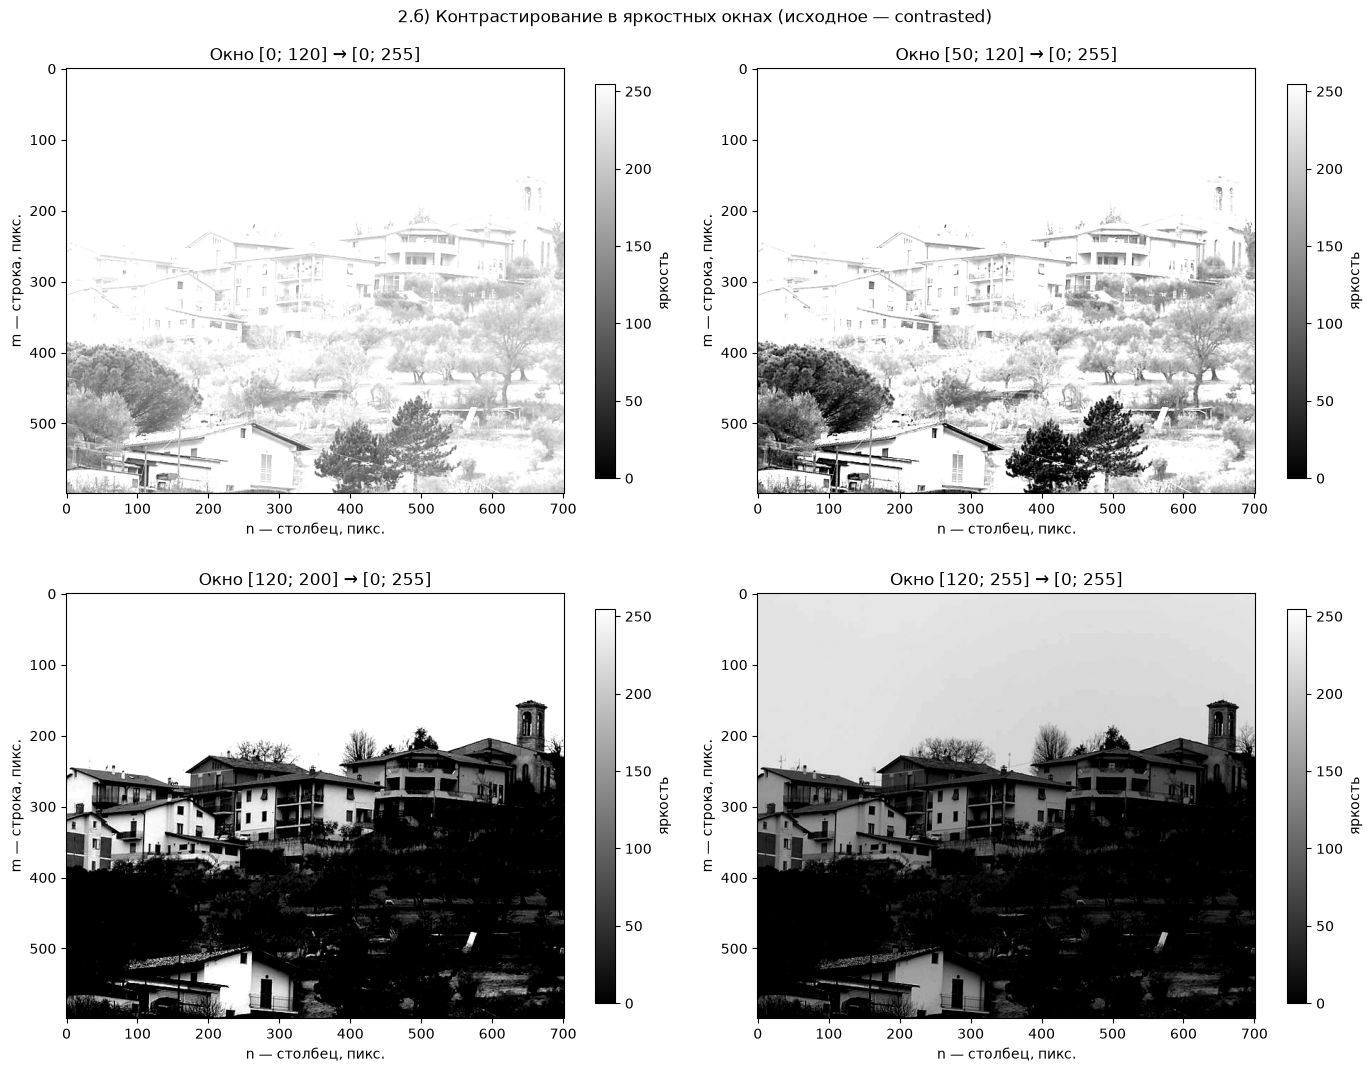

In [11]:
WINDOWS = [(0, 120), (50, 120), (120, 200), (120, 255)]
windowed = {(lo, hi): window(contrasted, lo, hi) for lo, hi in WINDOWS}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, ((lo, hi), img) in zip(axes.flat, windowed.items(), strict=True):
    image = ax.imshow(img, cmap="gray", vmin=0, vmax=P - 1)
    ax.set_title(f"Окно [{lo}; {hi}] → [0; 255]")
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
    fig.colorbar(image, ax=ax, label="яркость", shrink=0.8)
fig.suptitle("2.б) Контрастирование в яркостных окнах (исходное — contrasted)")
fig.tight_layout()
fig.savefig(FIGURES / "02b_windows.png", dpi=150)
plt.show()

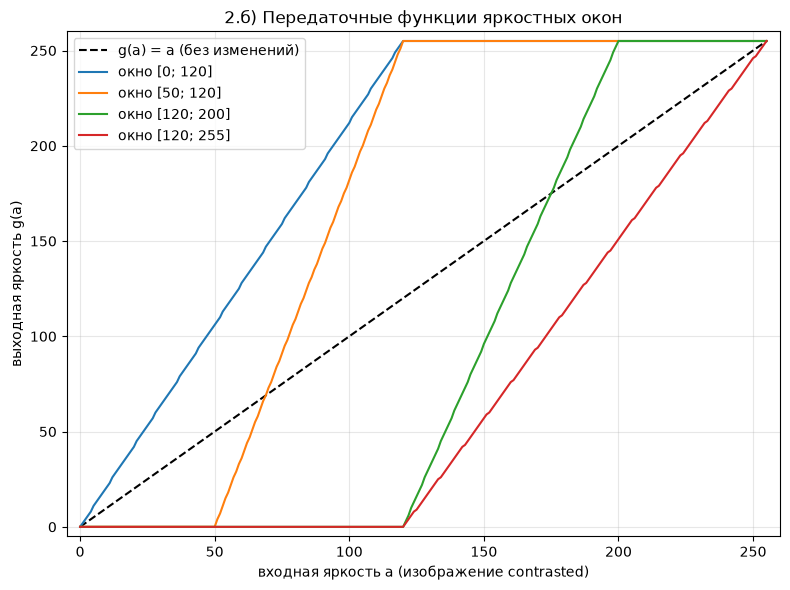

In [12]:
levels = np.arange(P, dtype=np.uint8)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(levels, levels, "k--", label="g(a) = a (без изменений)")
for lo, hi in WINDOWS:
    ax.plot(levels, window(levels, lo, hi), label=f"окно [{lo}; {hi}]")
# поля по краям, чтобы участки насыщения 0 и 255 не сливались с рамкой
ax.set_xlim(-5, P + 4)
ax.set_ylim(-5, P + 4)
ax.set_xlabel("входная яркость a (изображение contrasted)")
ax.set_ylabel("выходная яркость g(a)")
ax.set_title("2.б) Передаточные функции яркостных окон")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "02b_transfer.png", dpi=150)
plt.show()

In [13]:
rows = []
for (lo, hi), img in windowed.items():
    t = contrast_stats(img)
    black = (contrasted < lo).mean() * 100
    white = (contrasted > hi).mean() * 100
    rows.append(
        f"| [{lo}; {hi}] | {black:.1f}% | {white:.1f}% | {100 - black - white:.1f}% "
        f"| {t['rms']:.2f} | {t['haralick']:.1f} |"
    )
display(
    Markdown(
        "| Окно | Ниже окна ($a < w_{min}$) | Выше окна ($a > w_{max}$) | Внутри окна "
        "| $\\sigma$ | Контраст Харалика ($d=1,\\ \\alpha=0^\\circ$) |\n|:---:|:---:|:---:|:---:|:---:|:---:|\n"
        + "\n".join(rows)
    )
)

| Окно | Ниже окна ($a < w_{min}$) | Выше окна ($a > w_{max}$) | Внутри окна | $\sigma$ | Контраст Харалика ($d=1,\ \alpha=0^\circ$) |
|:---:|:---:|:---:|:---:|:---:|:---:|
| [0; 120] | 0.0% | 62.9% | 37.1% | 36.55 | 151.7 |
| [50; 120] | 0.9% | 62.9% | 36.2% | 61.62 | 419.1 |
| [120; 200] | 37.1% | 38.3% | 24.6% | 117.50 | 439.3 |
| [120; 255] | 37.1% | 0.0% | 62.9% | 100.95 | 181.8 |

In [14]:
cases = [(gray, s["a_min"], s["a_max"]), (gray, p_lo, p_hi)]
cases += [(contrasted, lo, hi) for lo, hi in WINDOWS]
for img, lo, hi in cases:
    ref = rescale_intensity(img, in_range=(lo, hi), out_range=(0, 255))
    assert np.array_equal(window(img, lo, hi), np.round(ref).astype(np.uint8))
print(
    "window совпадает с skimage.exposure.rescale_intensity для min-max, перцентилей и всех окон"
)

window совпадает с skimage.exposure.rescale_intensity для min-max, перцентилей и всех окон


### Выводы по пункту 2

- Min-max контрастирование растянуло [80; 255] на [0; 255] с коэффициентом k = 255/175 ≈ 1.46: σ выросла с 44.2 до 64.4 (×k), контраст Харалика — с 45.4 до 96.5 (×k² ≈ 2.12), контраст Михельсона и глобальный контраст стали равны 1. Средняя яркость снизилась со 191.6 до 162.7 — изображение потемнело, потому что тёмный край растянут до 0.
- Число различных яркостей не изменилось (172): растяжение только раздвигает имеющиеся уровни, оставляя между ними пустые ячейки (84 из 256) — на гистограмме видна «гребёнка». Линейное преобразование не создаёт новой информации.
- Min-max чувствителен к хвостам гистограммы: ~1 % пикселей (редкий тёмный хвост 80–113 и светлые 247–255) занимает 43 из 175 единиц динамического диапазона, поэтому растяжение слабое (k ≈ 1.46). Дело не в единичных выбросах: даже без 11 крайних пикселей диапазон [84; 254] дал бы k = 1.5. Растяжение по перцентилям 1–99 % ([114; 246]) отсекает хвосты: k ≈ 1.93, σ = 85.2, контраст Харалика 165.7 — изображение заметно контрастнее. Цена: обрезан ~1 % пикселей, а чисто чёрными или белыми стали 3.6 % (граница 246 пришлась на пик неба — 9 960 пикселей); различных уровней осталось 133 вместо 172.
- Окно работает как «лупа». [0; 120] раскрывает тёмные детали (деревья, тени), но 63 % изображения (дома, небо) уходит в белое. [120; 255], наоборот, детализирует дома и небо, а 37 % (растительность) становится чёрным. [120; 200] выделяет средние тона, насыщая 75 % пикселей. [50; 120] — самое узкое окно (растяжение ×3.6): самые тёмные сосны и тени уходят в чёрное, светлая растительность белеет, а полутона деревьев становятся особенно контрастными.
- В узких окнах ([50; 120], [120; 200]) σ и контраст Харалика очень велики (σ до 117, Харалик ≈ 420–440), но во многом за счёт насыщения: большие области становятся чисто чёрными или белыми, а на их границах возникают скачки 0↔255. Высокое значение метрики контраста ≠ больше различимых деталей.

## 3. Гамма-коррекция изображения

Гамма-коррекция — нелинейное отображение яркостей степенной передаточной функцией (исходное — результат 2.а, его диапазон уже $[0; 255]$):

$$g(a) = \left(\frac{a - a_{min}}{a_{max} - a_{min}}\right)^{\gamma}(P - 1)$$

Нормированная яркость $x \in [0; 1]$ возводится в степень $\gamma$. Концы $0$ и $1$ остаются на месте, поэтому, в отличие от яркостного окна, ничего не насыщается. При $\gamma < 1$ кривая выгнута вверх — изображение светлеет, при $\gamma > 1$ выгнута вниз — темнеет, $\gamma = 1$ — без изменений. (В некоторых программах параметр задают обратным, $1/\gamma$; здесь — как в scikit-image.)

У результата 2.а $a_{min} = 0$, $a_{max} = 255$, поэтому $x = a / 255$, и в коде гамма вызывается с окном $[0; P - 1]$.

Локальный наклон кривой $g'(a) = \gamma\,x^{\gamma - 1}\cdot\frac{P - 1}{a_{max} - a_{min}}$ (здесь множитель равен 1) показывает, где различия яркостей растут ($g' > 1$), а где сжимаются ($g' < 1$). Граница $g' = 1$: $a^* = (P - 1)\,\gamma^{1/(1-\gamma)}$.

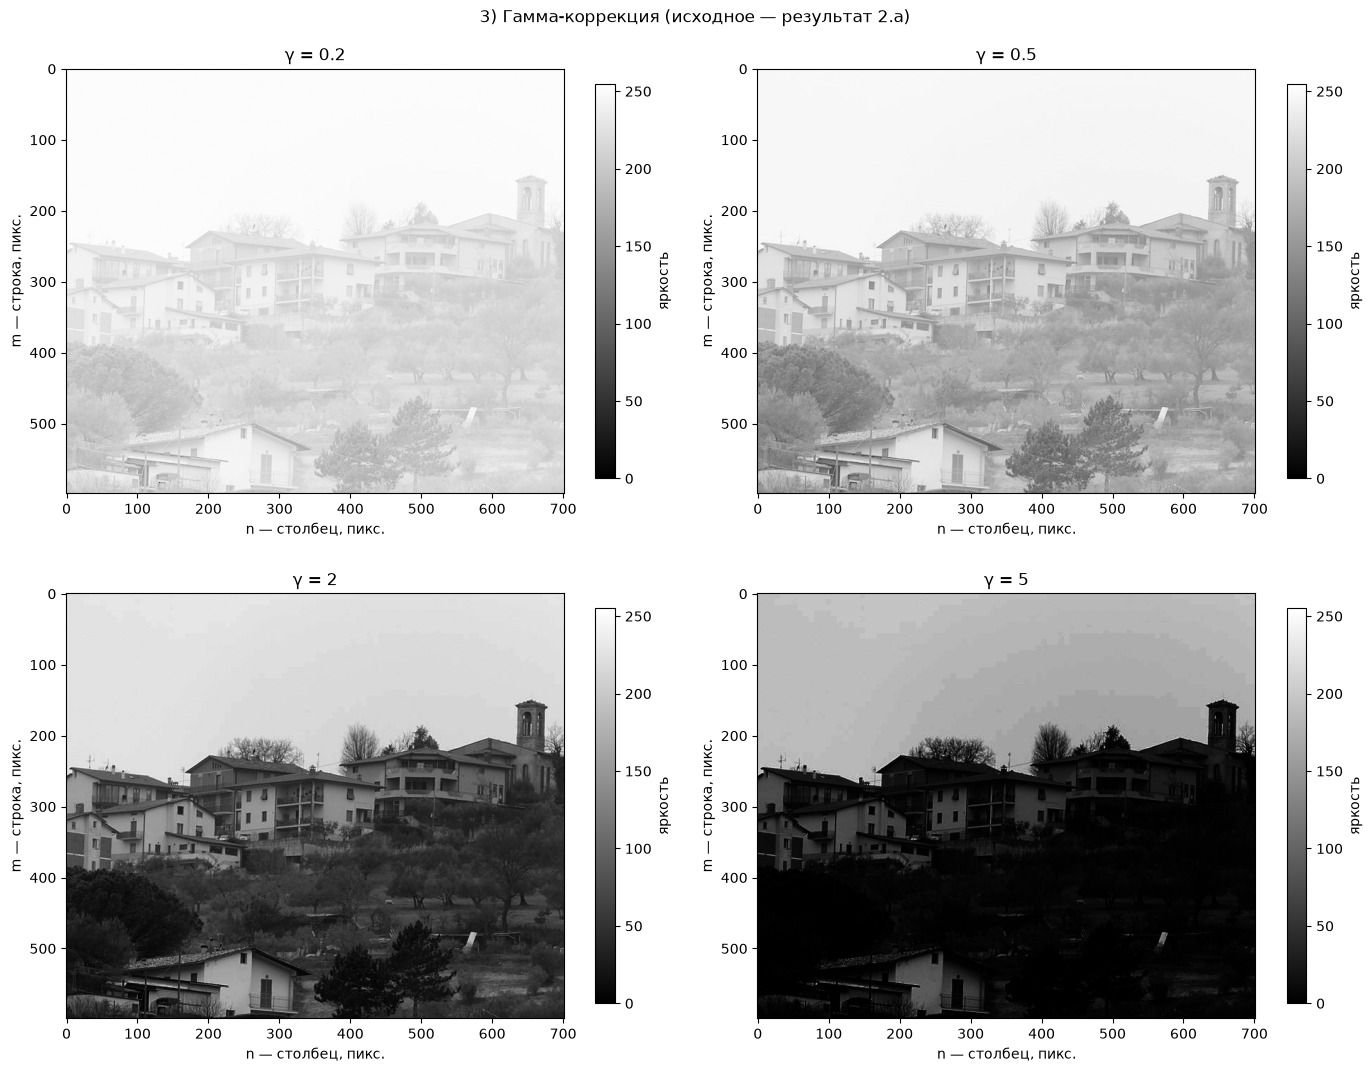

In [15]:
GAMMAS = [0.2, 0.5, 2, 5]
gammas = {g: window(contrasted, 0, P - 1, gamma=g) for g in GAMMAS}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (g, img) in zip(axes.flat, gammas.items(), strict=True):
    image = ax.imshow(img, cmap="gray", vmin=0, vmax=P - 1)
    ax.set_title(f"γ = {g}")
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
    fig.colorbar(image, ax=ax, label="яркость", shrink=0.8)
fig.suptitle("3) Гамма-коррекция (исходное — результат 2.а)")
fig.tight_layout()
fig.savefig(FIGURES / "03_gamma.png", dpi=150)
plt.show()

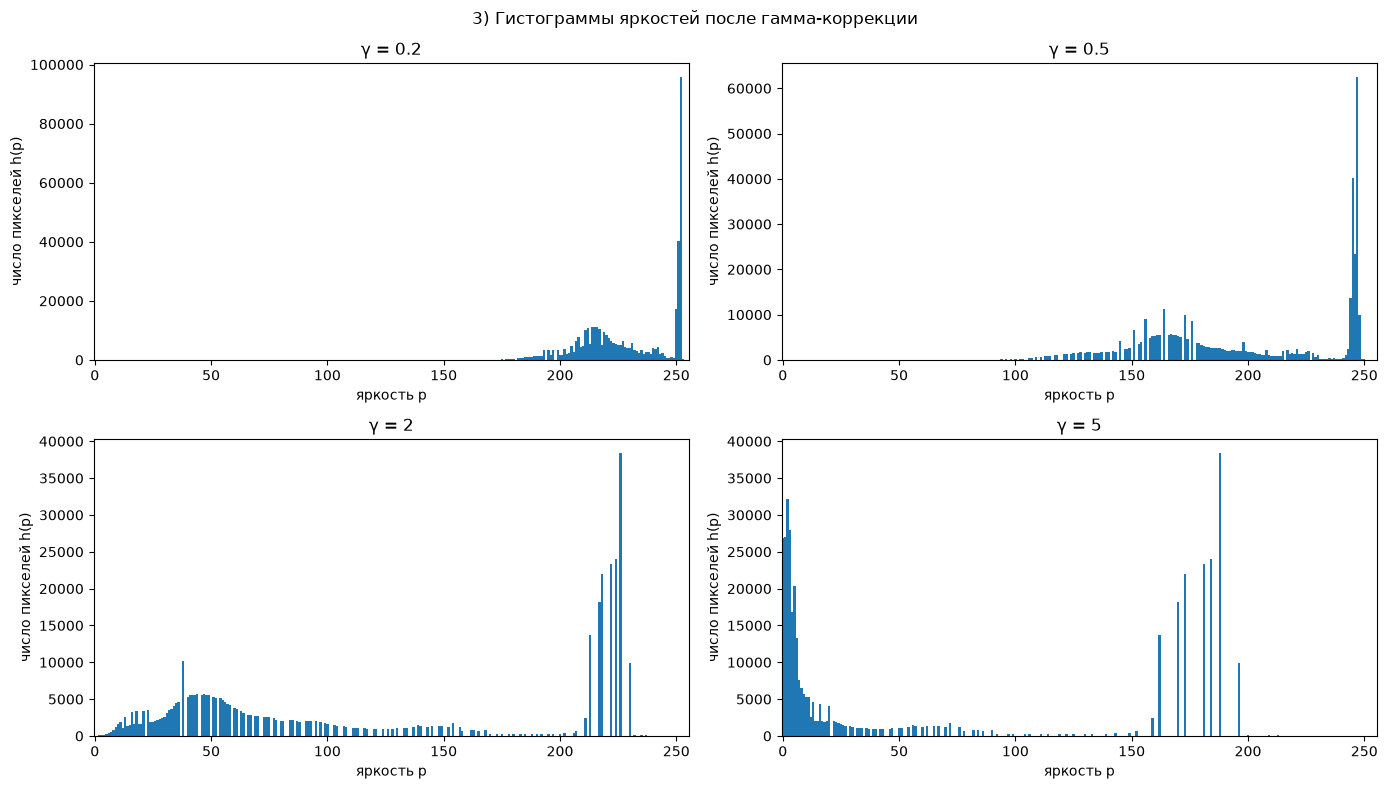

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (g, img) in zip(axes.flat, gammas.items(), strict=True):
    show_hist(ax, img, f"γ = {g}")
fig.suptitle("3) Гистограммы яркостей после гамма-коррекции")
fig.tight_layout()
fig.savefig(FIGURES / "03_gamma_hist.png", dpi=150)
plt.show()

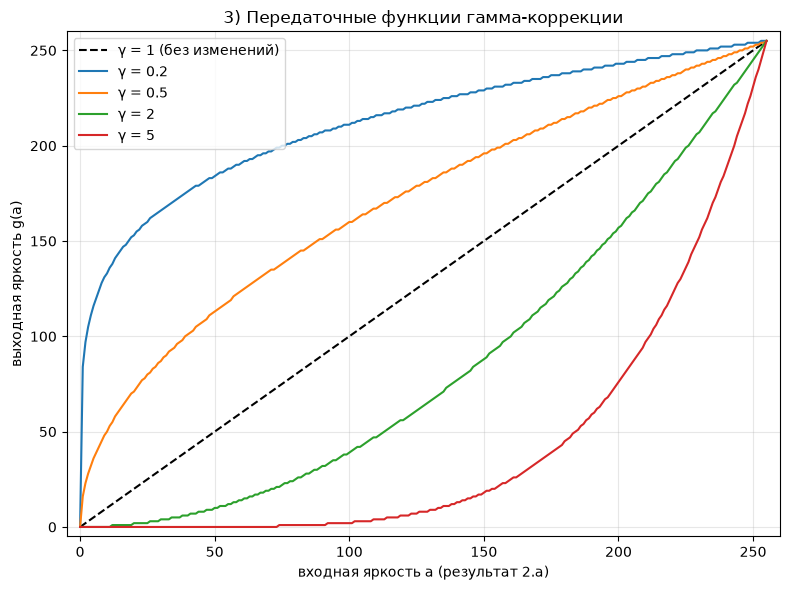

In [17]:
levels = np.arange(P, dtype=np.uint8)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(levels, levels, "k--", label="γ = 1 (без изменений)")
for g in GAMMAS:
    ax.plot(levels, window(levels, 0, P - 1, gamma=g), label=f"γ = {g}")
# поля по краям, чтобы концы кривых не сливались с рамкой
ax.set_xlim(-5, P + 4)
ax.set_ylim(-5, P + 4)
ax.set_xlabel("входная яркость a (результат 2.а)")
ax.set_ylabel("выходная яркость g(a)")
ax.set_title("3) Передаточные функции гамма-коррекции")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "03_gamma_transfer.png", dpi=150)
plt.show()

In [18]:
table_rows = [("исходное (результат 2.а)", contrasted)]
table_rows += [(f"γ = {g}", img) for g, img in gammas.items()]
lines = []
for name, img in table_rows:
    t = contrast_stats(img)
    lines.append(
        f"| {name} | {t['mean']:.1f} | {t['rms']:.1f} | {t['haralick']:.1f} "
        f"| {t['n_levels']} |"
    )
display(
    Markdown(
        "| Изображение | Средняя яркость | $\\sigma$ "
        "| Контраст Харалика ($d=1,\\ \\alpha=0^\\circ$) | Число различных яркостей |\n"
        "|:---|:---:|:---:|:---:|:---:|\n" + "\n".join(lines)
    )
)

| Изображение | Средняя яркость | $\sigma$ | Контраст Харалика ($d=1,\ \alpha=0^\circ$) | Число различных яркостей |
|:---|:---:|:---:|:---:|:---:|
| исходное (результат 2.а) | 162.7 | 64.4 | 96.5 | 172 |
| γ = 0.2 | 229.8 | 20.0 | 14.6 | 100 |
| γ = 0.5 | 199.3 | 41.8 | 52.7 | 151 |
| γ = 2 | 120.1 | 83.1 | 112.3 | 144 |
| γ = 5 | 74.1 | 82.2 | 72.8 | 90 |

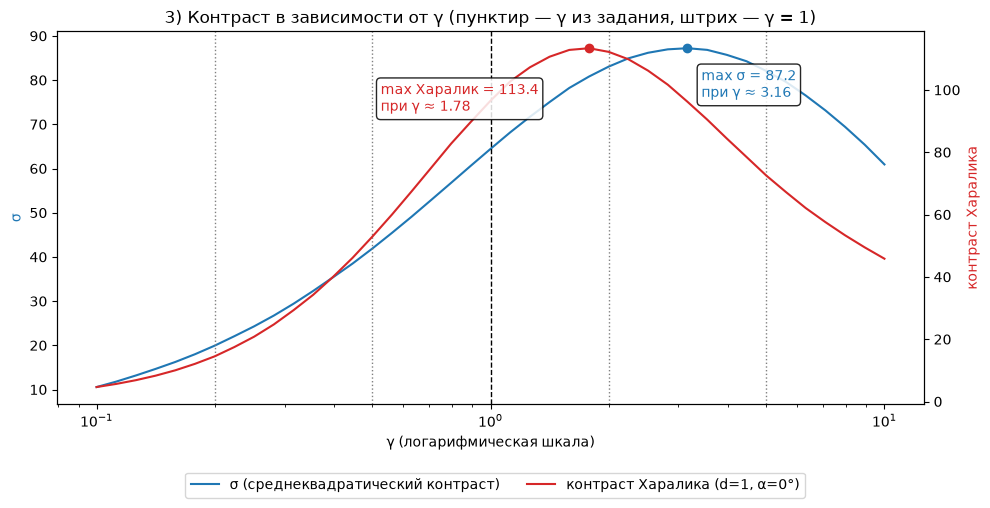

In [19]:
sweep = np.geomspace(0.1, 10, 41)
sweep_stats = [contrast_stats(window(contrasted, 0, P - 1, gamma=g)) for g in sweep]
sigma = np.array([t["rms"] for t in sweep_stats])
haralick = np.array([t["haralick"] for t in sweep_stats])
i, j = int(sigma.argmax()), int(haralick.argmax())

fig, ax_s = plt.subplots(figsize=(10, 5))
ax_h = ax_s.twinx()
ax_s.semilogx(sweep, sigma, color="tab:blue", label="σ (среднеквадратический контраст)")
ax_h.semilogx(sweep, haralick, color="tab:red", label="контраст Харалика (d=1, α=0°)")
ax_s.plot(sweep[i], sigma[i], "o", color="tab:blue")
ax_s.annotate(
    f"max σ = {sigma[i]:.1f}\nпри γ ≈ {sweep[i]:.2f}",
    (sweep[i], sigma[i]),
    textcoords="offset points",
    xytext=(10, -35),
    color="tab:blue",
    bbox={"boxstyle": "round", "fc": "white", "alpha": 0.85},
)
ax_h.plot(sweep[j], haralick[j], "o", color="tab:red")
ax_h.annotate(
    f"max Харалик = {haralick[j]:.1f}\nпри γ ≈ {sweep[j]:.2f}",
    (sweep[j], haralick[j]),
    textcoords="offset points",
    xytext=(-150, -45),
    color="tab:red",
    bbox={"boxstyle": "round", "fc": "white", "alpha": 0.85},
)
for g in GAMMAS:
    ax_s.axvline(g, color="gray", linestyle=":", linewidth=1)
ax_s.axvline(1, color="black", linestyle="--", linewidth=1)
ax_s.set_xlabel("γ (логарифмическая шкала)")
ax_s.set_ylabel("σ", color="tab:blue")
ax_h.set_ylabel("контраст Харалика", color="tab:red")
ax_s.set_title("3) Контраст в зависимости от γ (пунктир — γ из задания, штрих — γ = 1)")
fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIGURES / "03_gamma_sweep.png", dpi=150)
plt.show()

In [20]:
for g, img in gammas.items():
    assert np.array_equal(img, adjust_gamma(contrasted, g))
print("window(..., gamma) совпадает с skimage.exposure.adjust_gamma для всех γ")

window(..., gamma) совпадает с skimage.exposure.adjust_gamma для всех γ


### Выводы по пункту 3

- Гамма-коррекция изменяет яркости нелинейно, но концы шкалы (0 и 255) остаются на месте — в отличие от яркостного окна, ничего не насыщается.
- γ < 1 осветляет изображение: средняя яркость растёт со 162.7 до 199.3 (γ = 0.5) и 229.8 (γ = 0.2). Для нашей светлой картинки это вредно: кривая круче диагонали только в тенях (a ≲ 64 при γ = 0.5, a ≲ 34 при γ = 0.2), а большинство пикселей светлые — там различия сжимаются. σ падает с 64.4 до 41.8 и 20.0, контраст Харалика — с 96.5 до 52.7 и 14.6; при γ = 0.2 изображение почти белое.
- γ > 1 затемняет и растягивает светлую часть шкалы (a ≳ 128 при γ = 2, a ≳ 171 при γ = 5), где лежит большинство пикселей: туман, дома, небо. При γ = 2 σ = 83.1 и контраст Харалика 112.3 — лучший результат из четырёх: дымка ослабевает, дома и деревья становятся отчётливее.
- При γ = 5 изображение слишком тёмное (средняя 74.1): тени сжаты почти в 0, различных уровней осталось 90 из 172 — детали в тёмных областях слились.
- Сжатие уровней — общая цена нелинейности: где наклон кривой меньше 1, соседние яркости округляются в одно значение (151, 144, 100 и 90 уровней вместо 172). Где наклон больше 1, уровни, наоборот, раздвигаются с промежутками: при γ = 5 пик неба на гистограмме распался на редкие столбики (≈160–200), и на плавном градиенте неба появились заметные ступеньки (постеризация).
- «Оптимальная» γ зависит от метрики: σ максимальна при γ ≈ 3.2 (87.2), контраст Харалика — при γ ≈ 1.8 (113.4). σ поощряет разнесение яркостей к краям шкалы, даже ценой потери деталей, а Харалик — различия соседних пикселей. Для визуального восприятия разумен выбор γ ≈ 2.

## 4. Выравнивание гистограмм

### 4.а) Гистограмма и накопленная гистограмма

Гистограмма $h(p)$ — число пикселей яркости $p$. Накопленная гистограмма

$$H(p) = \frac{1}{MN}\sum_{q=0}^{p} h(q)$$

— доля пикселей с яркостью не больше $p$; она растёт от 0 до 1. Где пикселей много, $H$ растёт круто; где их нет — идёт горизонтально. Исходное изображение — результат 2.а.

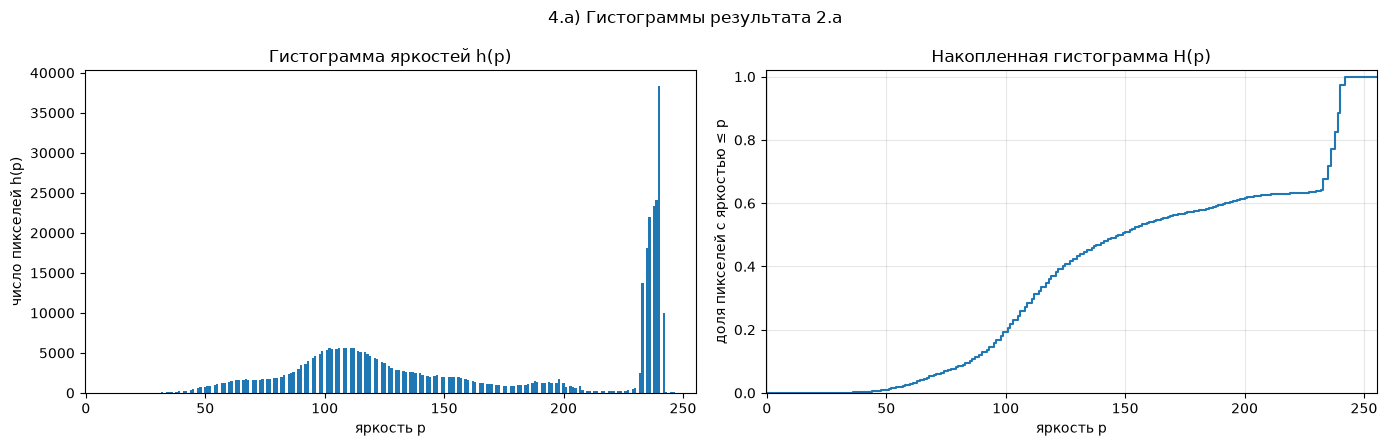

In [21]:
fig, (ax_h, ax_c) = plt.subplots(1, 2, figsize=(14, 4.5))
show_hist(ax_h, contrasted, "Гистограмма яркостей h(p)")
ax_c.plot(np.arange(P), cumulative_histogram(contrasted), drawstyle="steps-post")
ax_c.set_xlim(-0.5, P - 0.5)
ax_c.set_ylim(0, 1.02)
ax_c.set_title("Накопленная гистограмма H(p)")
ax_c.set_xlabel("яркость p")
ax_c.set_ylabel("доля пикселей с яркостью ≤ p")
ax_c.grid(alpha=0.3)
fig.suptitle("4.а) Гистограммы результата 2.а")
fig.tight_layout()
fig.savefig(FIGURES / "04a_hist.png", dpi=150)
plt.show()

### 4.б) Выравнивание гистограммы по заданному распределению

Если заменить каждую яркость $a$ на $H(a)$, новые значения распределятся на $[0; 1]$ **приблизительно равномерно**: $H(a)$ — доля пикселей не ярче $a$, то есть «ранг» пикселя. (Точно равномерно — только для непрерывного распределения яркостей; одинаковые яркости получают одинаковый ранг, поэтому в дискретном изображении ранги немного сдвинуты вверх.) Чтобы получить другое распределение с функцией распределения $F$, применяем к рангам обратную функцию:

$$g(a) = F^{-1}\big(H(a)\big), \qquad F(z) = \frac{\int_0^z f(t)\,dt}{\int_0^{P-1} f(t)\,dt}.$$

Для равномерной плотности $F^{-1}(y) = (P-1)\,y$ и $g(a) = (P-1)\,H(a)$ — классическое выравнивание гистограммы.

| Желаемое распределение | $f(a)$ ($k$ — нормировочный коэффициент) |
|---|---|
| равномерное | $f(a) = \text{const}$ |
| треугольное | $f(a) = k\,a$ при $0 \le a < 128$; $f(a) = k\,(255 - a)$ при $128 \le a \le 255$ |
| правое треугольное | $f(a) = k\,a$ |
| левое треугольное | $f(a) = k\,(255 - a)$ |

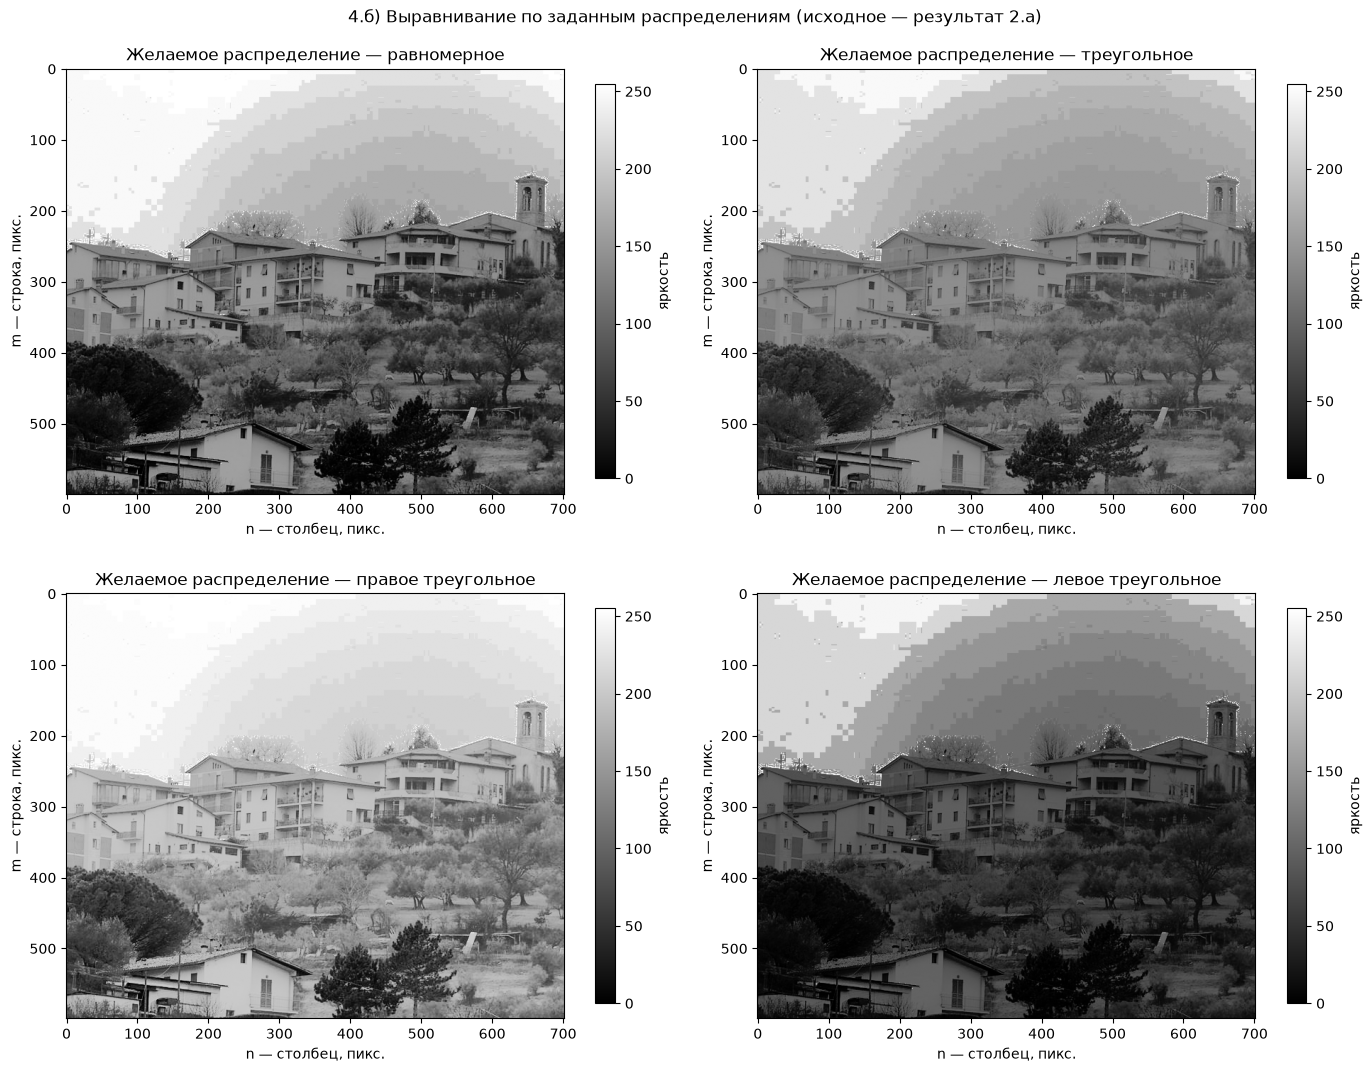

In [22]:
DISTRIBUTIONS = {
    "равномерное": np.ones_like,
    "треугольное": lambda a: np.where(a < 128, a, P - 1 - a),
    "правое треугольное": lambda a: a,
    "левое треугольное": lambda a: P - 1 - a,
}
luts = {name: match_lut(contrasted, pdf) for name, pdf in DISTRIBUTIONS.items()}
equalized = {name: lut[contrasted] for name, lut in luts.items()}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (name, img) in zip(axes.flat, equalized.items(), strict=True):
    image = ax.imshow(img, cmap="gray", vmin=0, vmax=P - 1)
    ax.set_title(f"Желаемое распределение — {name}")
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
    fig.colorbar(image, ax=ax, label="яркость", shrink=0.8)
fig.suptitle("4.б) Выравнивание по заданным распределениям (исходное — результат 2.а)")
fig.tight_layout()
fig.savefig(FIGURES / "04b_images.png", dpi=150)
plt.show()

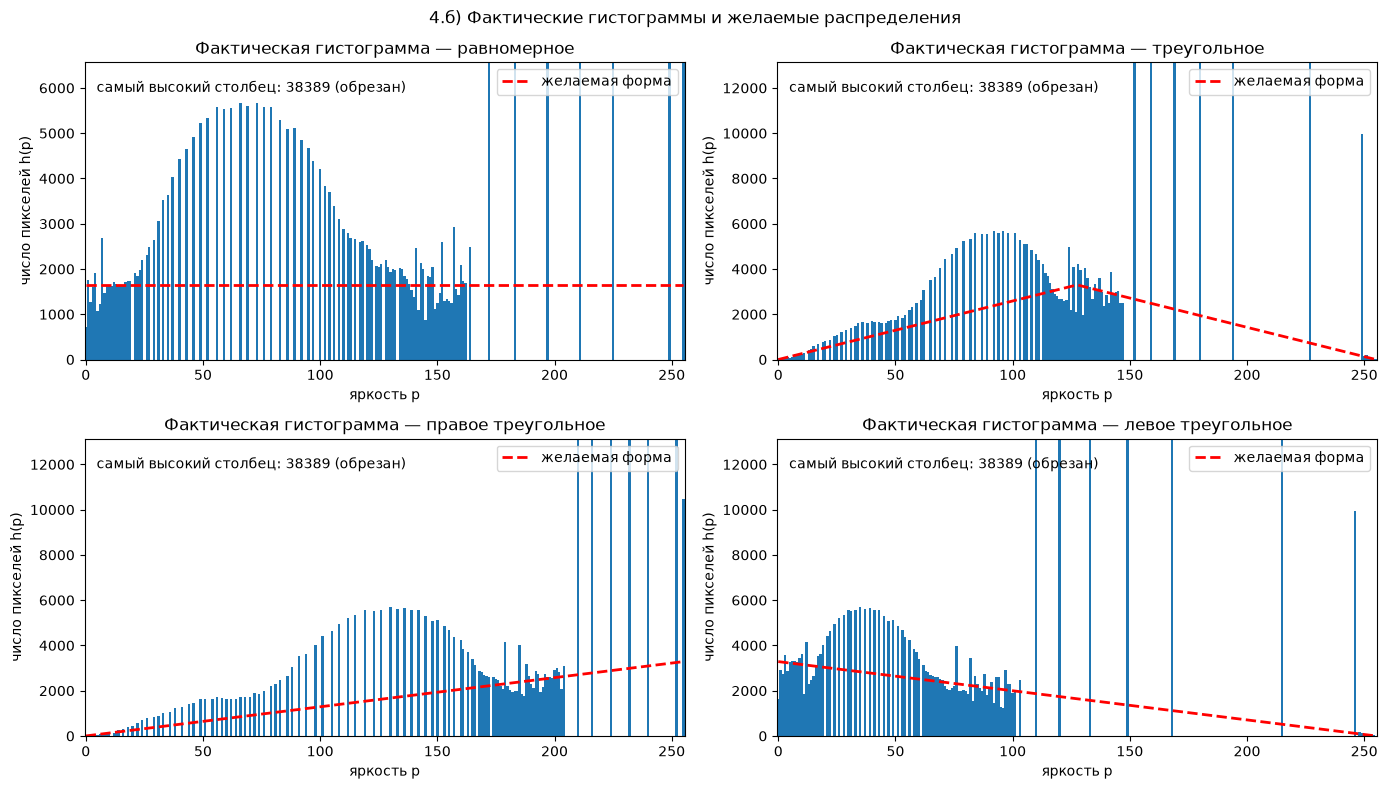

In [23]:
levels = np.arange(P, dtype=np.float64)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (name, img) in zip(axes.flat, equalized.items(), strict=True):
    show_hist(ax, img, f"Фактическая гистограмма — {name}")
    f = DISTRIBUTIONS[name](levels)
    expected = img.size * f / f.sum()
    ax.plot(levels, expected, "r--", linewidth=2, label="желаемая форма")
    # пик неба во много раз выше остальных столбцов — обрезаем ось и подписываем
    peak = int(histogram(img).max())
    ax.set_ylim(0, 4 * expected.max())
    ax.text(
        0.02, 0.9, f"самый высокий столбец: {peak} (обрезан)", transform=ax.transAxes
    )
    ax.legend(loc="upper right")
fig.suptitle("4.б) Фактические гистограммы и желаемые распределения")
fig.tight_layout()
fig.savefig(FIGURES / "04b_hist.png", dpi=150)
plt.show()

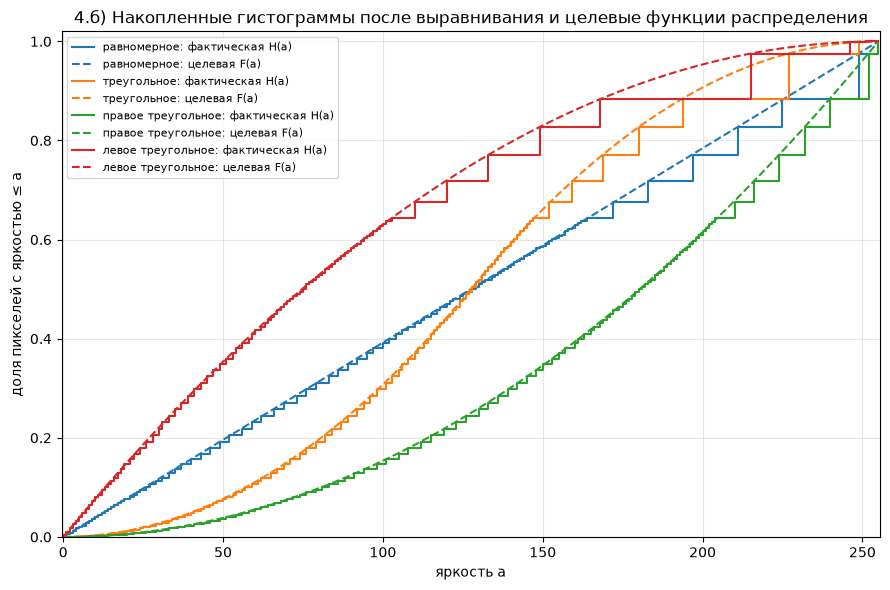

In [24]:
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, ax = plt.subplots(figsize=(9, 6))
for (name, img), color in zip(equalized.items(), colors, strict=True):
    ax.plot(
        levels,
        cumulative_histogram(img),
        color=color,
        drawstyle="steps-post",
        label=f"{name}: фактическая H(a)",
    )
    z, cdf = target_cdf(DISTRIBUTIONS[name])
    ax.plot(z, cdf, color=color, linestyle="--", label=f"{name}: целевая F(a)")
ax.set_xlim(-0.5, P - 0.5)
ax.set_ylim(0, 1.02)
ax.set_xlabel("яркость a")
ax.set_ylabel("доля пикселей с яркостью ≤ a")
ax.set_title(
    "4.б) Накопленные гистограммы после выравнивания и целевые функции распределения"
)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "04b_cumulative.png", dpi=150)
plt.show()

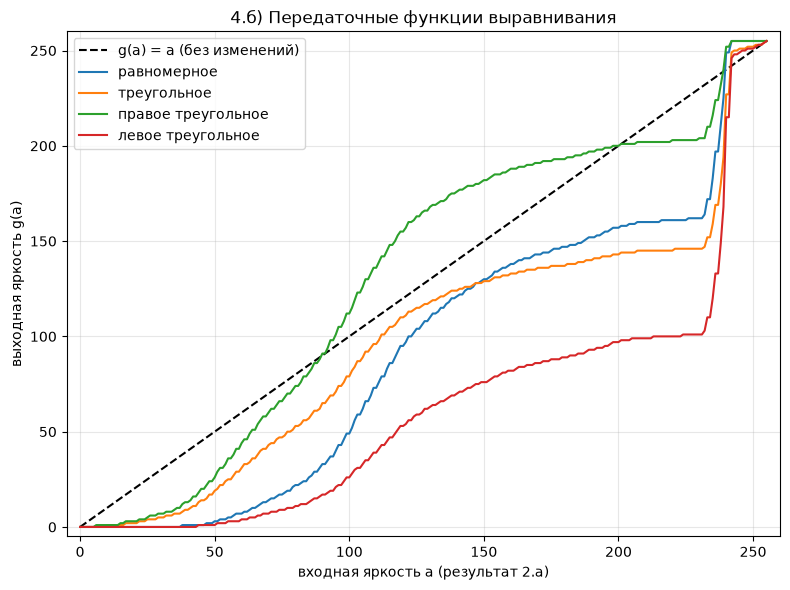

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(levels, levels, "k--", label="g(a) = a (без изменений)")
for name, lut in luts.items():
    ax.plot(levels, lut, label=name)
# поля по краям, чтобы концы кривых не сливались с рамкой
ax.set_xlim(-5, P + 4)
ax.set_ylim(-5, P + 4)
ax.set_xlabel("входная яркость a (результат 2.а)")
ax.set_ylabel("выходная яркость g(a)")
ax.set_title("4.б) Передаточные функции выравнивания")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "04b_transfer.png", dpi=150)
plt.show()

In [26]:
table_rows = [("исходное (результат 2.а)", contrasted), *equalized.items()]
lines = []
for name, img in table_rows:
    t = contrast_stats(img)
    lines.append(
        f"| {name} | {t['mean']:.1f} | {t['rms']:.1f} | {t['haralick']:.1f} "
        f"| {t['n_levels']} |"
    )
display(
    Markdown(
        "| Изображение | Средняя яркость | $\\sigma$ "
        "| Контраст Харалика ($d=1,\\ \\alpha=0^\\circ$) | Число различных яркостей |\n"
        "|:---|:---:|:---:|:---:|:---:|\n" + "\n".join(lines)
    )
)

| Изображение | Средняя яркость | $\sigma$ | Контраст Харалика ($d=1,\ \alpha=0^\circ$) | Число различных яркостей |
|:---|:---:|:---:|:---:|:---:|
| исходное (результат 2.а) | 162.7 | 64.4 | 96.5 | 172 |
| равномерное | 130.8 | 76.4 | 177.5 | 109 |
| треугольное | 131.3 | 56.1 | 109.0 | 114 |
| правое треугольное | 172.2 | 61.2 | 172.7 | 117 |
| левое треугольное | 90.0 | 66.6 | 109.4 | 99 |

In [27]:
ref = np.round(equalize_hist(contrasted, nbins=P) * (P - 1)).astype(np.uint8)
assert np.array_equal(equalized["равномерное"], ref)
H = cumulative_histogram(contrasted)
closed = {
    "треугольное": np.where(
        H < 0.5, (P - 1) * np.sqrt(H / 2), (P - 1) * (1 - np.sqrt((1 - H) / 2))
    ),
    "правое треугольное": (P - 1) * np.sqrt(H),
    "левое треугольное": (P - 1) * (1 - np.sqrt(1 - H)),
}
for name, g in closed.items():
    assert np.array_equal(luts[name], np.round(g).astype(np.uint8))
print(
    "Равномерное совпадает с skimage.exposure.equalize_hist, треугольные — с аналитическими формулами"
)

Равномерное совпадает с skimage.exposure.equalize_hist, треугольные — с аналитическими формулами


### Выводы по пункту 4 (4.а–4.б)

- Накопленная гистограмма результата 2.а почти не растёт в тёмной части (H(40) ≈ 0.003), круто растёт на 80–140, где сосредоточены растительность и стены (с 0.09 до 0.48), и делает резкий скачок ≈ 0.09 у пика неба — 9 % пикселей имеют одну и ту же яркость.
- Равномерное выравнивание дало наибольший контраст: σ 76.4 (было 64.4), контраст Харалика 177.5 (было 96.5). Передаточная функция круто растёт там, где пикселей много, — именно эти яркости получают больше места на шкале.
- Идеально ровной гистограммы не получается: пиксели одинаковой яркости нельзя разделить, поэтому пик неба остаётся пиком, а рядом с ним — пустые промежутки. Различных уровней стало меньше (109 вместо 172): редкие соседние яркости сливаются. Фактическая H(a) — лестница, ступеньки которой касаются целевой F(a) углами, а между ними лежат ниже неё. По той же причине столбцы фактической гистограммы выше пунктира желаемой формы: между ними пустые уровни, и только в среднем по соседним уровням высота совпадает с желаемой.
- Форма желаемого распределения задаёт общий тон: правое треугольное даёт светлое изображение (средняя 172.2), левое — тёмное (90.0), симметричное треугольное стягивает яркости к середине шкалы (σ 56.1 — даже меньше исходного).
- Глобальное выравнивание не учитывает, где на изображении объекты: светлые области с яркостью ≥ 228 (небо и светлые стены) — это 37 % пикселей, но всего 19 различных яркостей; после выравнивания они получают 37 % шкалы (93 уровня из 255), хотя деталей в них немного. Передаточная функция на участке неба почти вертикальна (~10 входных уровней растянуты почти на 90), поэтому на небе проявились ступеньки и квадраты 8×8 от сжатия JPEG, незаметные в исходном изображении: выравнивание усиливает и шум, и артефакты. Этот недостаток устраняют адаптивные методы (4.в–4.г).

### 4.в) Адаптивное выравнивание гистограммы (AHE)

Глобальное выравнивание строит **одну** передаточную функцию на всё изображение. Адаптивное (AHE) строит **свою** функцию для каждой области:

1. Изображение разбивается на $k \times k$ фрагментов («черепицу»).
2. В каждом фрагменте считается локальная гистограмма.
3. Для каждого фрагмента строится своя передаточная функция выравнивания.
4. Чтобы на границах фрагментов не было «швов», значение в каждом пикселе получается билинейной интерполяцией передаточных функций четырёх ближайших фрагментов.

Размер окна — размер фрагмента в пикселях: $\lceil M/k \rceil \times \lceil N/k \rceil$. AHE — это CLAHE без отсечения (уровень отсечения 1.0). Исходное изображение — результат 2.а.

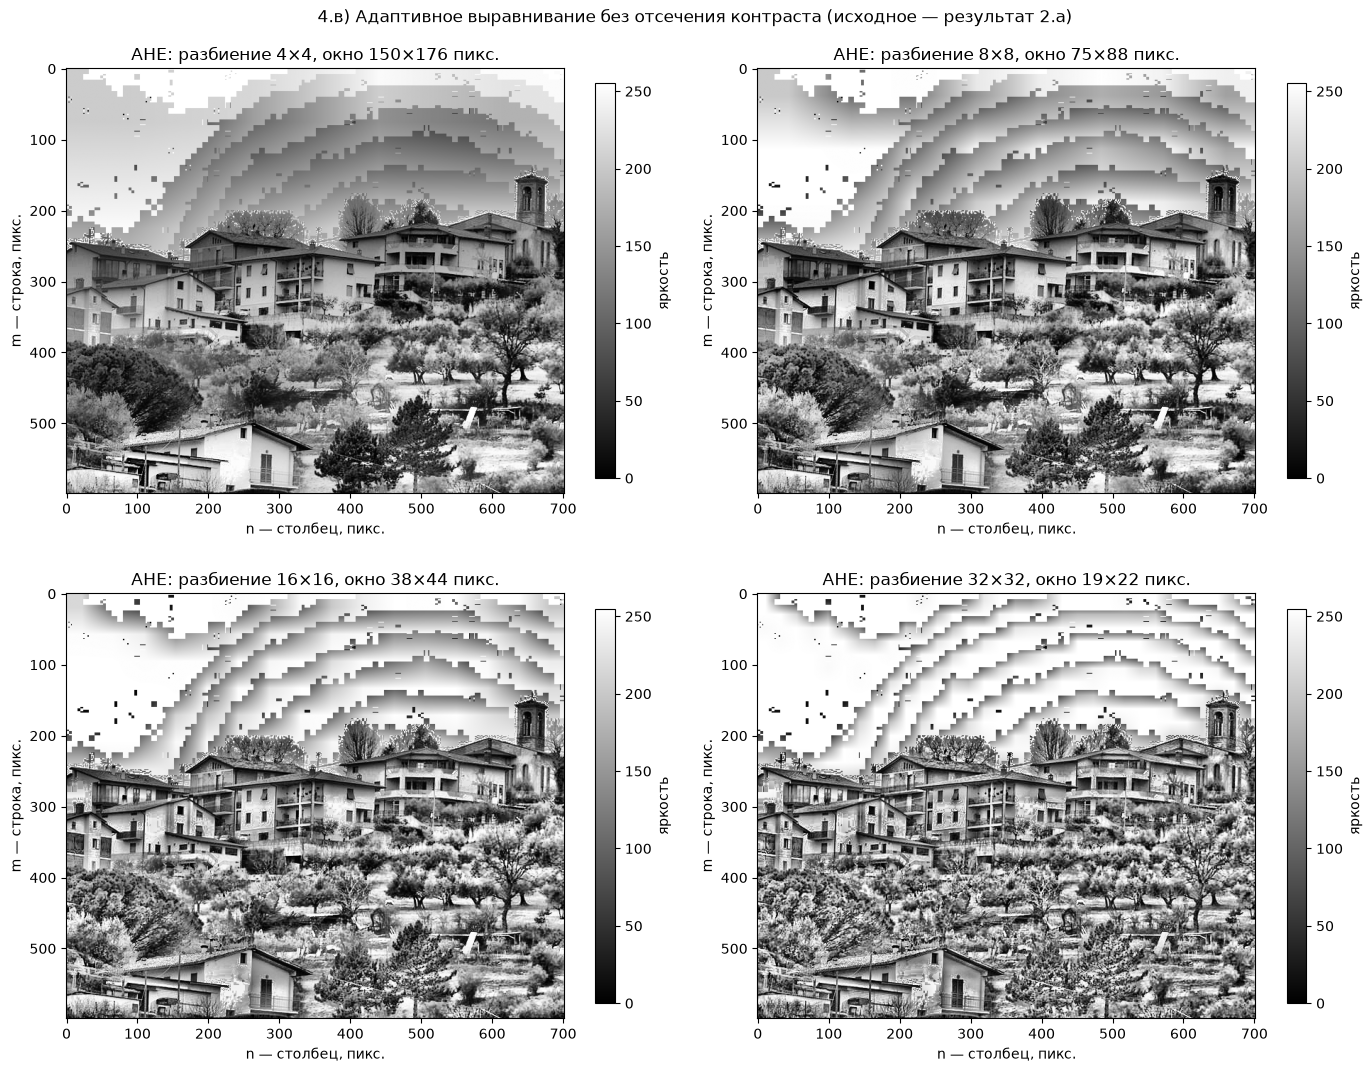

In [28]:
TILES = [4, 8, 16, 32]
ahe = {t: clahe(contrasted, t, 1.0) for t in TILES}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (t, img) in zip(axes.flat, ahe.items(), strict=True):
    h, w = tile_size(contrasted.shape, t)
    image = ax.imshow(img, cmap="gray", vmin=0, vmax=P - 1)
    ax.set_title(f"AHE: разбиение {t}×{t}, окно {h}×{w} пикс.")
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
    fig.colorbar(image, ax=ax, label="яркость", shrink=0.8)
fig.suptitle(
    "4.в) Адаптивное выравнивание без отсечения контраста (исходное — результат 2.а)"
)
fig.tight_layout()
fig.savefig(FIGURES / "04c_ahe.png", dpi=150)
plt.show()

In [29]:
lines = []
for t, img in ahe.items():
    h, w = tile_size(contrasted.shape, t)
    st = contrast_stats(img)
    lines.append(
        f"| {t}×{t} | {h}×{w} | {st['mean']:.1f} | {st['rms']:.1f} "
        f"| {st['haralick']:.1f} | {st['n_levels']} |"
    )
display(
    Markdown(
        "| Разбиение | Размер окна, пикс. | Средняя яркость | $\\sigma$ "
        "| Контраст Харалика ($d=1,\\ \\alpha=0^\\circ$) | Число различных яркостей |\n"
        "|:---:|:---:|:---:|:---:|:---:|:---:|\n" + "\n".join(lines)
    )
)

| Разбиение | Размер окна, пикс. | Средняя яркость | $\sigma$ | Контраст Харалика ($d=1,\ \alpha=0^\circ$) | Число различных яркостей |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 4×4 | 150×176 | 140.7 | 65.9 | 549.8 | 256 |
| 8×8 | 75×88 | 148.0 | 69.2 | 788.7 | 256 |
| 16×16 | 38×44 | 157.1 | 73.1 | 1069.8 | 256 |
| 32×32 | 19×22 | 163.9 | 75.9 | 1462.3 | 256 |

#### Зачем нужна интерполяция

Для сравнения — три варианта при одном и том же разбиении 8×8: глобальное выравнивание (4.б), выравнивание каждого фрагмента **отдельно, без интерполяции**, и AHE с билинейной интерполяцией. «Швы» оцениваются средним модулем перепада яркости между соседними строками на границах фрагментов, делённым на тот же перепад внутри фрагментов (≈ 1 — швов нет).

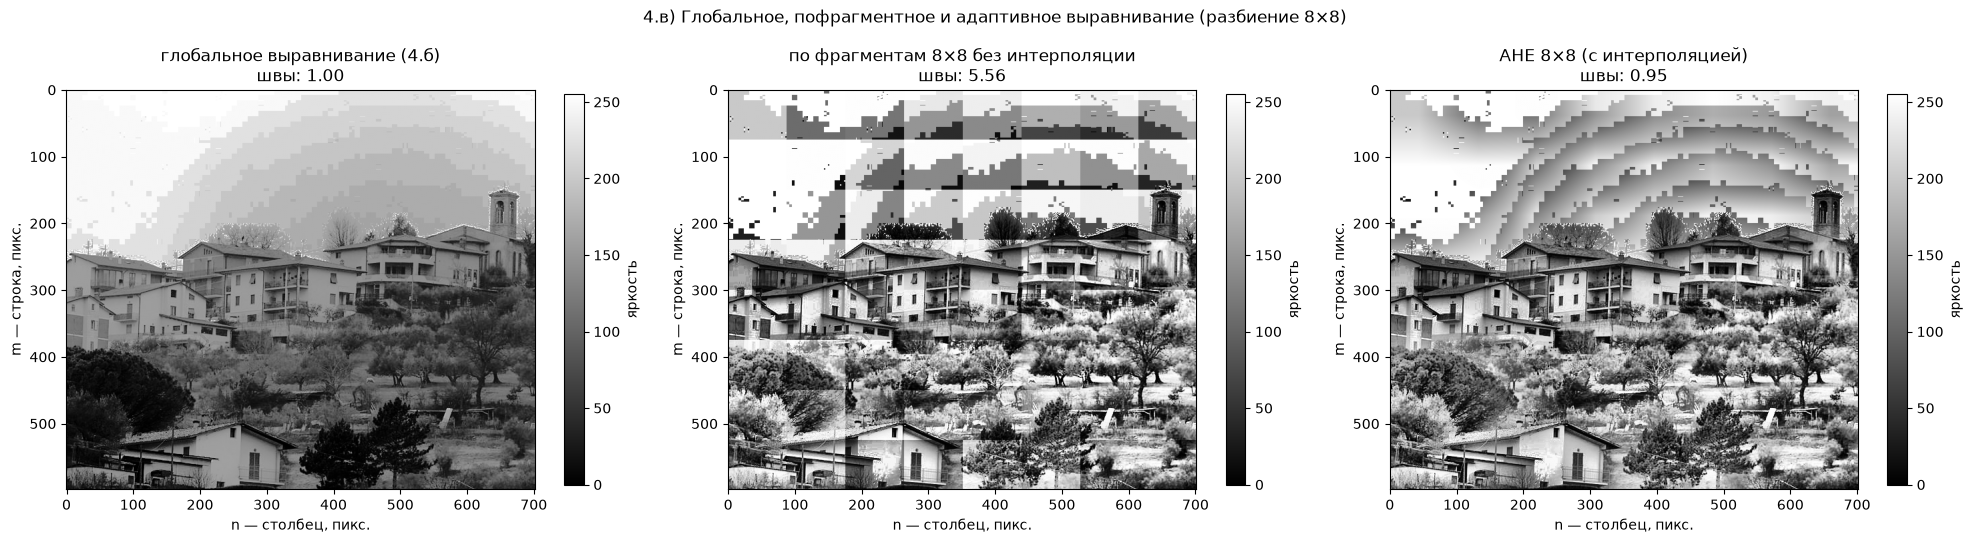

In [30]:
def seam_ratio(img: NDArray[np.uint8], tiles: int) -> float:
    """Считает отношение перепада яркости на границах фрагментов к перепаду внутри.

    Args:
        img: NDArray[np.uint8] - Серое изображение.
        tiles: int - Число фрагментов по каждой стороне.

    Returns:
        float - Отношение средних модулей перепада между соседними строками.

    """
    rows = [r[-1] for r in np.array_split(np.arange(img.shape[0]), tiles)][:-1]
    d = np.abs(np.diff(img.astype(int), axis=0))
    return float(d[rows].mean() / np.delete(d, rows, axis=0).mean())


tiled = tile_equalize(contrasted, 8)
seams = {
    "глобальное выравнивание (4.б)": equalized["равномерное"],
    "по фрагментам 8×8 без интерполяции": tiled,
    "AHE 8×8 (с интерполяцией)": ahe[8],
}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (name, img) in zip(axes, seams.items(), strict=True):
    image = ax.imshow(img, cmap="gray", vmin=0, vmax=P - 1)
    ax.set_title(f"{name}\nшвы: {seam_ratio(img, 8):.2f}")
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
    fig.colorbar(image, ax=ax, label="яркость", shrink=0.8)
fig.suptitle("4.в) Глобальное, пофрагментное и адаптивное выравнивание (разбиение 8×8)")
fig.tight_layout()
fig.savefig(FIGURES / "04c_seams.png", dpi=150)
plt.show()

### 4.г) Адаптивное выравнивание с ограничением контраста (CLAHE)

У AHE наклон локальной передаточной функции пропорционален высоте локальной гистограммы: в однородной области (небо) почти все пиксели одной яркости, и узкий диапазон растягивается на всю шкалу — усиливается шум. CLAHE перед выравниванием **отсекает** локальную гистограмму на заданном уровне, а отсечённый избыток равномерно распределяет по всем уровням. Это ограничивает наклон передаточной функции, а значит, и усиление контраста.

Уровень отсечения $c \in (0; 1]$ задаёт порог столбца локальной гистограммы: в scikit-image порог $= c \cdot n$, где $n$ — число пикселей окна (у MATLAB `adapthisteq` порог отсчитывается от средней высоты столбца $n/256$, поэтому шкалы совпадают только на концах). 1.0 — отсечения нет (AHE), чем меньше уровень — тем сильнее ограничение. Если порог ниже средней высоты столбца ($c < 1/256 \approx 0.0039$), гистограмма срезается до ровной «полки» и передаточная функция становится линейной. Разбиение — 8×8, $n = 75 \cdot 88 = 6600$.

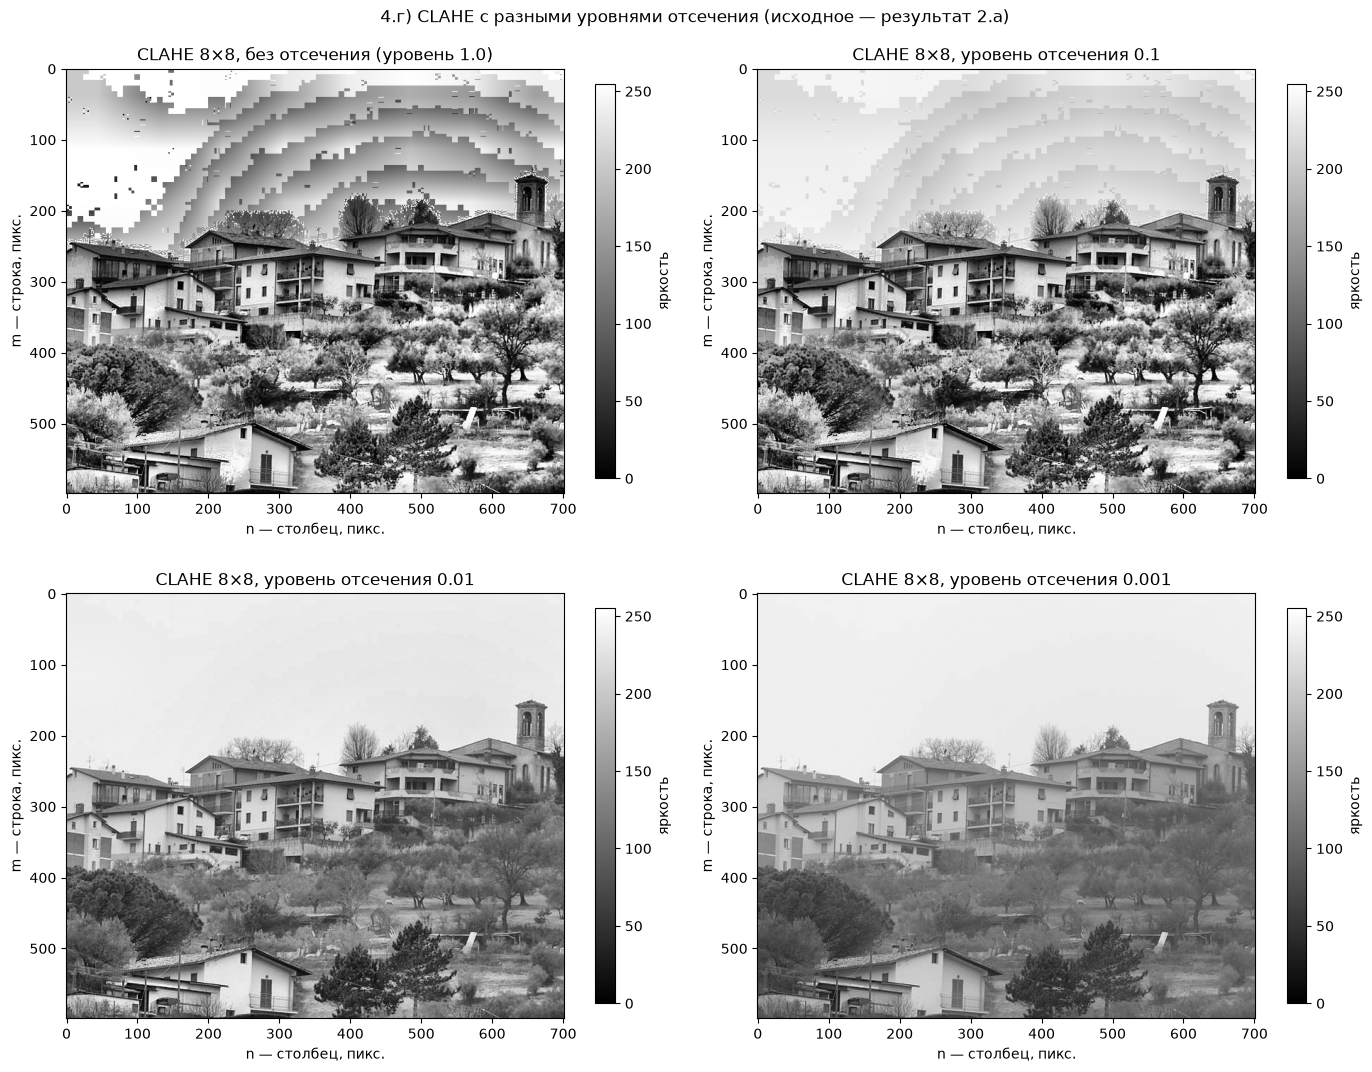

In [31]:
CLIPS = [1.0, 0.1, 0.01, 0.001]
clahes = {cl: clahe(contrasted, 8, cl) for cl in CLIPS}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (cl, img) in zip(axes.flat, clahes.items(), strict=True):
    image = ax.imshow(img, cmap="gray", vmin=0, vmax=P - 1)
    label = "без отсечения (уровень 1.0)" if cl == 1 else f"уровень отсечения {cl}"
    ax.set_title(f"CLAHE 8×8, {label}")
    ax.set_xlabel("n — столбец, пикс.")
    ax.set_ylabel("m — строка, пикс.")
    fig.colorbar(image, ax=ax, label="яркость", shrink=0.8)
fig.suptitle("4.г) CLAHE с разными уровнями отсечения (исходное — результат 2.а)")
fig.tight_layout()
fig.savefig(FIGURES / "04d_clahe.png", dpi=150)
plt.show()

In [32]:
lines = []
for cl, img in clahes.items():
    st = contrast_stats(img)
    lines.append(
        f"| {cl} | {st['mean']:.1f} | {st['rms']:.1f} | {st['haralick']:.1f} "
        f"| {st['n_levels']} |"
    )
display(
    Markdown(
        "| Уровень отсечения | Средняя яркость | $\\sigma$ "
        "| Контраст Харалика ($d=1,\\ \\alpha=0^\\circ$) | Число различных яркостей |\n"
        "|:---:|:---:|:---:|:---:|:---:|\n" + "\n".join(lines)
    )
)

| Уровень отсечения | Средняя яркость | $\sigma$ | Контраст Харалика ($d=1,\ \alpha=0^\circ$) | Число различных яркостей |
|:---:|:---:|:---:|:---:|:---:|
| 1.0 | 148.0 | 69.2 | 788.7 | 256 |
| 0.1 | 161.9 | 71.2 | 663.7 | 256 |
| 0.01 | 161.9 | 67.7 | 247.6 | 255 |
| 0.001 | 162.3 | 64.7 | 96.8 | 178 |

### 4.д) Матрица и контраст Харалика до и после выравнивания ($d = 1$)

Сравниваются результат 2.а, глобальное равномерное выравнивание (4.б) и CLAHE 8×8 с уровнем отсечения 0.01 (стандартное значение по умолчанию). Матрицы нарисованы на **общей** логарифмической шкале цветов, чтобы их можно было сравнивать между собой.

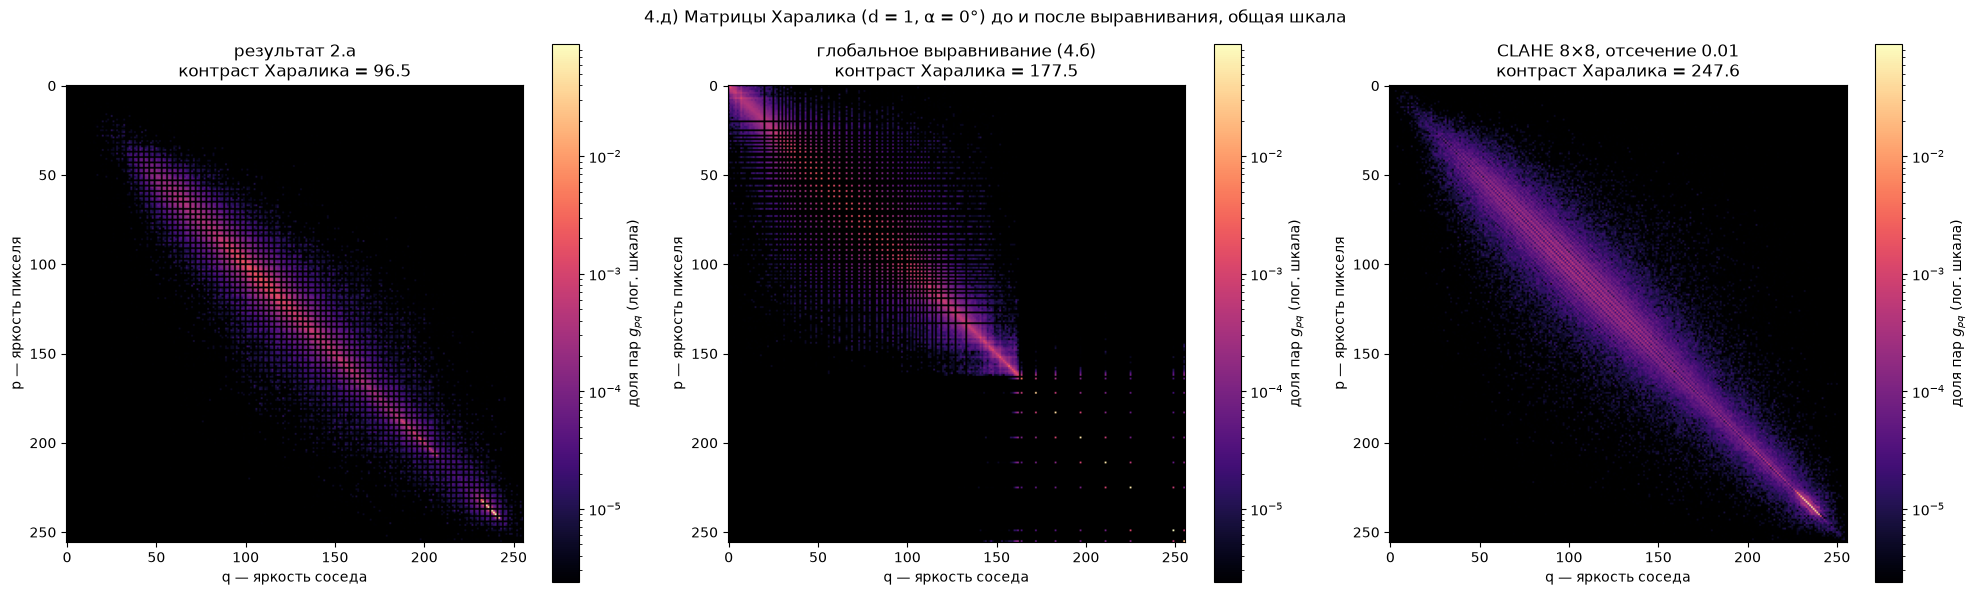

| Изображение | Контраст Харалика, $\alpha = 0^\circ$ | Контраст Харалика, $\alpha = 90^\circ$ |
|:---|:---:|:---:|
| результат 2.а | 96.5 | 116.7 |
| глобальное выравнивание (4.б) | 177.5 | 219.1 |
| CLAHE 8×8, отсечение 0.01 | 247.6 | 290.8 |

In [33]:
compare = {
    "результат 2.а": contrasted,
    "глобальное выравнивание (4.б)": equalized["равномерное"],
    "CLAHE 8×8, отсечение 0.01": clahes[0.01],
}
mats = {name: glcm(img, 1, 0) for name, img in compare.items()}
shared = LogNorm(
    vmin=min(float(m[m > 0].min()) for m in mats.values()),
    vmax=max(float(m.max()) for m in mats.values()),
)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, m) in zip(axes, mats.items(), strict=True):
    show_glcm(
        ax, m, f"{name}\nконтраст Харалика = {haralick_contrast(m):.1f}", norm=shared
    )
fig.suptitle(
    "4.д) Матрицы Харалика (d = 1, α = 0°) до и после выравнивания, общая шкала"
)
fig.tight_layout()
fig.savefig(FIGURES / "04e_glcm.png", dpi=150)
plt.show()

lines = [
    f"| {name} | {haralick_contrast(glcm(img, 1, 0)):.1f} "
    f"| {haralick_contrast(glcm(img, 1, 90)):.1f} |"
    for name, img in compare.items()
]
display(
    Markdown(
        "| Изображение | Контраст Харалика, $\\alpha = 0^\\circ$ "
        "| Контраст Харалика, $\\alpha = 90^\\circ$ |\n|:---|:---:|:---:|\n"
        + "\n".join(lines)
    )
)

### Выводы по пункту 4 (4.в–4.д)

- **AHE** выравнивает гистограмму в каждой области отдельно, поэтому проявляет локальные детали, невидимые после глобального выравнивания: фактуру стен, ветви деревьев, траву. Чем мельче разбиение, тем сильнее эффект: контраст Харалика растёт с 549.8 (4×4, окно 150×176) до 1462.3 (32×32, окно 19×22), σ — с 65.9 до 75.9. Используются все 256 уровней.
- Цена AHE — усиление шума и артефактов в однородных областях: в каждом окне неба почти все пиксели одной яркости, и узкий диапазон растягивается на всю шкалу. На небе появляются концентрические полосы и квадраты 8×8 от сжатия JPEG; при мелком разбиении изображение становится «жёстким» и зернистым.
- Выравнивание фрагментов по отдельности без интерполяции даёт резкие «швы»: перепад яркости на границах фрагментов в 5.56 раза больше, чем внутри. Билинейная интерполяция передаточных функций соседних фрагментов в AHE полностью их устраняет (отношение 0.95, как у глобального выравнивания — 1.00).
- **CLAHE** ограничивает наклон локальных передаточных функций, отсекая локальные гистограммы. С уменьшением уровня отсечения контраст Харалика монотонно падает: 788.7 (1.0, это AHE) → 663.7 (0.1) → 247.6 (0.01) → 96.8 (0.001, практически исходное изображение 96.5): порог 0.001 · 6600 ≈ 6 пикселей ниже средней высоты столбца (≈ 26), локальные гистограммы срезаются до ровной полки, и передаточные функции становятся линейными — результат не меняется вплоть до уровня ≈ 0.004. При уровне 0.1 полосы на небе ещё заметны, при 0.01 небо гладкое, а дома и деревья отчётливы — лучший компромисс между проявлением деталей и усилением шума. Качество при разбиении 8×8 удовлетворительное, менять размер разбиения не потребовалось.
- **Матрица Харалика (d = 1).** У результата 2.а и глобального выравнивания матрица «решётчатая»: заняты не все уровни яркости (гребёнка), а у глобального выравнивания светлая часть (небо) представлена отдельными точками — несколько далеко разнесённых уровней. У CLAHE диагональ сплошная и шире: задействованы почти все уровни (255 из 256), соседние пиксели различаются сильнее. Контраст Харалика при α = 0°: 96.5 → 177.5 (глобальное) → 247.6 (CLAHE 0.01); при α = 90°: 116.7 → 219.1 → 290.8 — выравнивание увеличивает различие соседних пикселей в обоих направлениях, CLAHE — сильнее всего.